<a href="https://colab.research.google.com/github/HarshPrajapati7/GridAttention/blob/main/GRIDTWIN24_FINAL_Research_Grade_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GRIDTWIN-24 · Research-grade day-ahead grid-demand forecasting

**Target:** 24 hourly `demand_mw` values for a specified ISO forecast date.  
**Dataset:** [Hack Day Lucknow — P2 Grid Demand Forecast](https://github.com/CodewithJha/hack-day-lucknow-datasets/tree/main/p2-grid-demand-forecast)

This notebook is built around the maintainers' documented data characteristics: 79,283 hourly rows (2015–2024), missing hours, typo-like extreme values, and operational covariates that begin partway through the history.

## Research protocol

1. Freeze the exact forecast date and discard all observations after the 23:00 issue origin **before** any data audit, anomaly review, feature construction, tuning or model selection.
2. Preserve raw demand. Create a separate, causal quality-reviewed training view; never silently delete anomalies from the audit or the raw evaluation.
3. Build point-in-time 24-horizon features. Every feature at origin O must be derivable from timestamps at or before O.
4. Compare seasonal baselines, LightGBM, CatBoost, GPU DLinear, GPU PatchTST and an optional Chronos-2 zero-shot challenger.
5. Use distributed rolling-origin validation, a separate chronological tuning block and a final untouched chronological holdout.
6. Select by **raw holdout-relevant metrics** (WAPE/MAE/RMSE), fold stability and prediction coverage. Also report quality-reviewed metrics as a sensitivity analysis.
7. Calibrate empirical P10/P90 intervals from out-of-time residuals against raw observations; report actual coverage and interval width.
8. Run automated stress tests for date cutoffs, future perturbations, timestamp anomalies, missing gaps, regime shifts, validation boundaries, model outputs and submission format.

**Forecast protocol:** forecast date D is issued after D−1 23:00 and predicts D 00:00 through D 23:00. The dataset README does not specify a timezone, so its timezone-naïve clock is preserved. Do not localise or shift it without an organiser-confirmed timezone/DST convention.

**Metric note:** this is continuous regression. “99% accuracy” is not a defined metric here. Report WAPE, MAE, RMSE, bias, peak error, interval coverage and performance against the same-date seasonal baseline. No architecture is assumed to win before the backtest.


**Important:** this is a forecasting regression task, not a classification task. There is no meaningful generic "99% accuracy" target. The final model is selected by leakage-safe out-of-time WAPE and fold stability, then checked against the untouched holdout and the seasonal baselines. If a baseline wins, the notebook retains it rather than forcing a more complex model.


## 0 · Runtime and configuration

Before running all cells:
- Set `FORECAST_DATE` to the exact ISO date supplied by the organisers. `None` means the day after the last timestamp only when the CSV ends at 23:00.
- Use a fresh Colab runtime. A T4 GPU accelerates neural / foundation-model challengers; LightGBM and CatBoost still run on CPU.
- Keep `RUN_CHRONOS2=True` for the optional pretrained challenger. If model download or API compatibility fails, it is skipped and logged; it is not silently scored.
- Do not edit holdout dates after inspecting holdout results. If you change modelling choices after seeing the holdout, create a new later test period.


In [ ]:
# Stable installs. Avoid upgrading pyarrow: Colab's CUDA data-science packages may pin it.
%pip -q install "lightgbm>=4.3,<5" "catboost>=1.2,<2" "optuna>=3.6,<5" "scikit-learn>=1.4,<2" "joblib>=1.3,<2" "requests>=2.31,<3"

In [ ]:
from __future__ import annotations
import os, sys, json, math, time, hashlib, random, warnings, platform, gc, zipfile, subprocess
from pathlib import Path
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
from catboost import CatBoostRegressor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---------------- USER CONFIG ----------------
DATA_URL = "https://raw.githubusercontent.com/CodewithJha/hack-day-lucknow-datasets/main/p2-grid-demand-forecast/history.csv"
EXPECTED_GIT_BLOB_SHA1 = "bbe04aab1d83f6a0226d30c9e3cf63b7ee5db68e"
EXPECTED_ROWS = 79_283

# Enter the exact organiser-provided ISO date, e.g. "2024-06-10".
# None forecasts the day immediately after the last complete day in the CSV.
FORECAST_DATE = None

# Temporal evaluation windows. These dates are taken only from the pre-forecast history.
HOLDOUT_DAYS = 28
TUNE_DAYS = 21
CV_FOLDS = 5
CV_DAYS = 14
MIN_TRAIN_DAYS = 365 * 2

# Conservative causal gross-error screening. Raw values are always retained and scored separately.
SEASONAL_HISTORY_WEEKS = 104
MIN_SEASONAL_PEERS = 12
EXTREME_HIGH_RATIO = 3.0
EXTREME_LOW_RATIO = 0.15
ROBUST_Z_THRESHOLD = 10.0
PERSISTENCE_HOURS = 4

# Model search/training. T4 is used by PatchTST/DLinear and Chronos-2 when available.
RUN_OPTUNA = True
OPTUNA_TRIALS = 30
RUN_DLINEAR = True
RUN_PATCHTST = True
RUN_CHRONOS2 = True                 # Optional; graceful fallback if install/model download fails.
NEURAL_LOOKBACK = 672               # 28 days of hourly history
NEURAL_MAX_EPOCHS = 70
NEURAL_PATIENCE = 10
NEURAL_BATCH_SIZE = 128
NEURAL_MAX_MISSING_FRACTION = 0.20
PATCH_LEN = 24
PATCH_STRIDE = 12
PATCH_D_MODEL = 96
PATCH_HEADS = 4
PATCH_LAYERS = 2
PATCH_DROPOUT = 0.20

# Use lagged operational variables only. Current/future generation and imports are never used.
USE_OPERATIONAL_CONTEXT = True
MIN_COVARIATE_COVERAGE = 0.20

OUTDIR = Path("/content/GRIDTWIN24_FINAL_OUTPUTS")
OUTDIR.mkdir(parents=True, exist_ok=True)

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    try: torch.set_float32_matmul_precision("high")
    except Exception: pass

print("Python:", platform.python_version())
print("pandas:", pd.__version__, "numpy:", np.__version__, "torch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
print("FORECAST_DATE:", FORECAST_DATE)

Python: 3.13.16
pandas: 2.2.3 numpy: 2.1.3 torch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
FORECAST_DATE: None


## 1 · Download and fingerprint the exact dataset

The CSV is downloaded directly from the official Hack Day Lucknow repository. The notebook records the SHA-256, Git blob SHA-1, row count, schema and date range for reproducibility. The repository README is a participant-facing description and may be updated separately from the CSV; a row-count or hash difference is therefore surfaced for review, not silently ignored.

When `FORECAST_DATE` is explicitly set, rows after the previous-day 23:00 issue time are excluded before numeric coercion, duplicate-conflict checks, anomaly analysis, feature construction, model selection or tuning. Only timestamps are parsed to determine the cutoff. The notebook records how many later rows were excluded.


In [ ]:
import requests

CSV_PATH = Path("/content/history.csv")
if not CSV_PATH.exists():
    response = requests.get(DATA_URL, timeout=180)
    response.raise_for_status()
    if len(response.content) < 1_000_000:
        raise RuntimeError(f"CSV download is unexpectedly small ({len(response.content):,} bytes).")
    CSV_PATH.write_bytes(response.content)

blob = CSV_PATH.read_bytes()
DATA_SHA256 = hashlib.sha256(blob).hexdigest()
GIT_BLOB_SHA1 = hashlib.sha1(b"blob " + str(len(blob)).encode() + b"\x00" + blob).hexdigest()
print("Downloaded bytes:", f"{len(blob):,}")
print("SHA-256:", DATA_SHA256)
print("Git blob SHA-1:", GIT_BLOB_SHA1)
if GIT_BLOB_SHA1 != EXPECTED_GIT_BLOB_SHA1:
    warnings.warn("Dataset Git blob SHA differs from the inspected version. Review schema/date changes before trusting results.")

raw = pd.read_csv(CSV_PATH, low_memory=False)
print("Raw shape:", raw.shape)
print("Columns:", raw.columns.tolist())
required = {"timestamp", "demand_mw"}
if not required.issubset(raw.columns):
    raise ValueError(f"Missing required columns: {required - set(raw.columns)}")
if len(raw) != EXPECTED_ROWS:
    warnings.warn(f"README lists {EXPECTED_ROWS:,} rows; downloaded file has {len(raw):,}. Continue only after reviewing the audit.")

Downloaded bytes: 5,240,286
SHA-256: 8af13c5a525398d8834cdbd0b034cc56724eb23b55df5ad9df674c327e24b297
Git blob SHA-1: bbe04aab1d83f6a0226d30c9e3cf63b7ee5db68e
Raw shape: (79283, 14)
Columns: ['timestamp', 'generation_mw', 'demand_mw', 'load_shedding', 'gas', 'liquid_fuel', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'india_tripura', 'india_adani', 'nepal']


## 2 · Timestamp integrity, duplicates and hidden-date cutoff

In [ ]:
import re

def parse_iso_forecast_date(value):
    if value is None or value == "":
        return None
    if not isinstance(value, str) or not re.fullmatch(r"\d{4}-\d{2}-\d{2}", value):
        raise ValueError(f"FORECAST_DATE must be an exact ISO calendar date YYYY-MM-DD, received {value!r}")
    try:
        return pd.Timestamp(value).normalize()
    except Exception as e:
        raise ValueError(f"Invalid ISO calendar date: {value!r}") from e


def make_hourly_history(raw_frame: pd.DataFrame, forecast_date=None):
    x = raw_frame.copy()
    x.columns = [str(c).strip() for c in x.columns]
    x = x.drop(columns=[c for c in x.columns if c.lower().startswith("unnamed:")], errors="ignore")
    if not {"timestamp", "demand_mw"}.issubset(x.columns):
        raise ValueError("timestamp and demand_mw columns are mandatory.")

    # Timestamps are the only fields inspected beyond an explicit forecast origin.
    x["timestamp_raw"] = x["timestamp"].astype(str)
    x["timestamp"] = pd.to_datetime(x["timestamp"], errors="coerce")
    if x["timestamp"].isna().any():
        raise ValueError(f"Unparseable timestamps: {int(x.timestamp.isna().sum())}; cannot safely identify rows before/after the cutoff.")
    if not pd.api.types.is_datetime64_any_dtype(x["timestamp"]):
        raise ValueError("Mixed timezone/offset timestamp values detected. Confirm the source timezone and DST convention explicitly.")
    if getattr(x["timestamp"].dt, "tz", None) is not None:
        raise ValueError("Timezone-aware timestamps found. Confirm source timezone and DST policy; do not silently convert.")

    data_last_timestamp = x["timestamp"].max()
    requested_day = parse_iso_forecast_date(forecast_date)
    if requested_day is None:
        if data_last_timestamp.hour != 23 or data_last_timestamp.minute != 0:
            raise ValueError("CSV does not end at 23:00. Set FORECAST_DATE explicitly so the 23:00 day-ahead origin is unambiguous.")
        forecast_day = data_last_timestamp.normalize() + pd.Timedelta(days=1)
    else:
        forecast_day = requested_day
    forecast_origin = forecast_day - pd.Timedelta(hours=1)

    # Enforce point-in-time scope before checking numeric values, duplicate conflicts,
    # outliers, missingness, feature availability, or selecting models.
    rows_after_issue_origin = int((x["timestamp"] > forecast_origin).sum())
    x = x.loc[x["timestamp"] <= forecast_origin].copy()
    if x.empty:
        raise ValueError("No observations exist at or before the requested forecast origin.")

    off_hour = (x.timestamp.dt.minute != 0) | (x.timestamp.dt.second != 0) | (x.timestamp.dt.microsecond != 0)
    if off_hour.any():
        raise ValueError(f"Off-hour timestamps at/before issue origin: {int(off_hour.sum())}; do not round timestamps silently.")

    value_cols = [c for c in x.columns if c not in ["timestamp", "timestamp_raw"]]
    coercions = []
    for c in value_cols:
        before = int(x[c].notna().sum())
        x[c] = pd.to_numeric(x[c], errors="coerce")
        coercions.append({"column": c, "non_numeric_coerced_to_nan": before - int(x[c].notna().sum())})
    x[value_cols] = x[value_cols].replace([np.inf, -np.inf], np.nan)

    exact_duplicates = int(x.drop(columns=["timestamp_raw"]).duplicated().sum())
    x = x.drop_duplicates(subset=["timestamp"] + value_cols, keep="first")
    conflict_mask = x.timestamp.duplicated(keep=False)
    conflicts = x.loc[conflict_mask].sort_values("timestamp").copy()
    if len(conflicts):
        conflicts.to_csv(OUTDIR / "conflicting_duplicate_timestamps.csv", index=False)
        raise ValueError(f"Conflicting rows share timestamps at/before issue origin ({len(conflicts)} rows). See conflicting_duplicate_timestamps.csv; no automatic averaging was applied.")

    x = x.drop(columns=["timestamp_raw"], errors="ignore").sort_values("timestamp").set_index("timestamp")
    if not x.index.is_monotonic_increasing or x.index.has_duplicates:
        raise RuntimeError("Timestamp order/uniqueness invariant failed.")
    if forecast_origin not in x.index:
        raise ValueError(f"The exact issue-origin observation {forecast_origin} is absent. A day-ahead forecast must be issued from a recorded 23:00 timestamp.")

    full_index = pd.date_range(x.index.min(), forecast_origin, freq="h", name="timestamp")
    hourly = x.reindex(full_index)
    if forecast_origin < full_index.min() + pd.Timedelta(days=28):
        raise ValueError("Forecast date has less than 28 days of historical context.")
    missing_hour_index = full_index.difference(x.index)
    report = pd.DataFrame(coercions)
    return hourly, forecast_day, forecast_origin, data_last_timestamp, missing_hour_index, exact_duplicates, report, rows_after_issue_origin

hourly, forecast_day, forecast_origin, DATA_LAST_TIMESTAMP, missing_hour_index, exact_duplicates, coercion_report, ROWS_AFTER_ISSUE_ORIGIN = make_hourly_history(raw, FORECAST_DATE)
print("CSV last timestamp (metadata only):", DATA_LAST_TIMESTAMP)
print("Rows excluded after issue origin:", ROWS_AFTER_ISSUE_ORIGIN)
print("Forecast date:", forecast_day.date())
print("Issue origin:", forecast_origin)
print("Modelling rows retained through origin:", len(hourly))
print("Missing hourly slots through origin:", len(missing_hour_index))
print("Exact duplicate rows removed within point-in-time history:", exact_duplicates)
display(coercion_report)
assert hourly.index.max() == forecast_origin
assert not (hourly.index > forecast_origin).any()
assert missing_hour_index.isin(hourly.index).all()
assert len(missing_hour_index) == int(hourly.loc[missing_hour_index].isna().all(axis=1).sum())


CSV last timestamp (metadata only): 2024-06-16 23:00:00
Rows excluded after issue origin: 0
Forecast date: 2024-06-17
Issue origin: 2024-06-16 23:00:00
Modelling rows retained through origin: 80328
Missing hourly slots through origin: 1045
Exact duplicate rows removed within point-in-time history: 0


,column,non_numeric_coerced_to_nan
0,generation_mw,0
1,demand_mw,0
2,load_shedding,0
3,gas,0
4,liquid_fuel,0
5,coal,0
6,hydro,0
7,solar,0
8,wind,0
9,india_bheramara_hvdc,0


## 3 · Data profile and target quality

,demand_mw
count,79283.000000
mean,8461.528739
std,2549.550226
min,6.000000
0.1%,3222.794000
0.5%,3813.000000
1%,4094.640000
5%,4995.000000
50%,8089.000000
95%,13000.000000


,non_missing,missing_pct,first_available,last_available,unique_values
india_adani,0,100.000000,NaT,NaT,0
nepal,0,100.000000,NaT,NaT,0
wind,9146,88.614182,2023-06-01 06:00:00,2024-06-16 23:00:00,66
solar,58766,26.842446,2017-09-20 06:00:00,2024-06-16 23:00:00,847
generation_mw,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,20051
liquid_fuel,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,5552
gas,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,4791
load_shedding,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,1968
demand_mw,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,10178
coal,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,4515


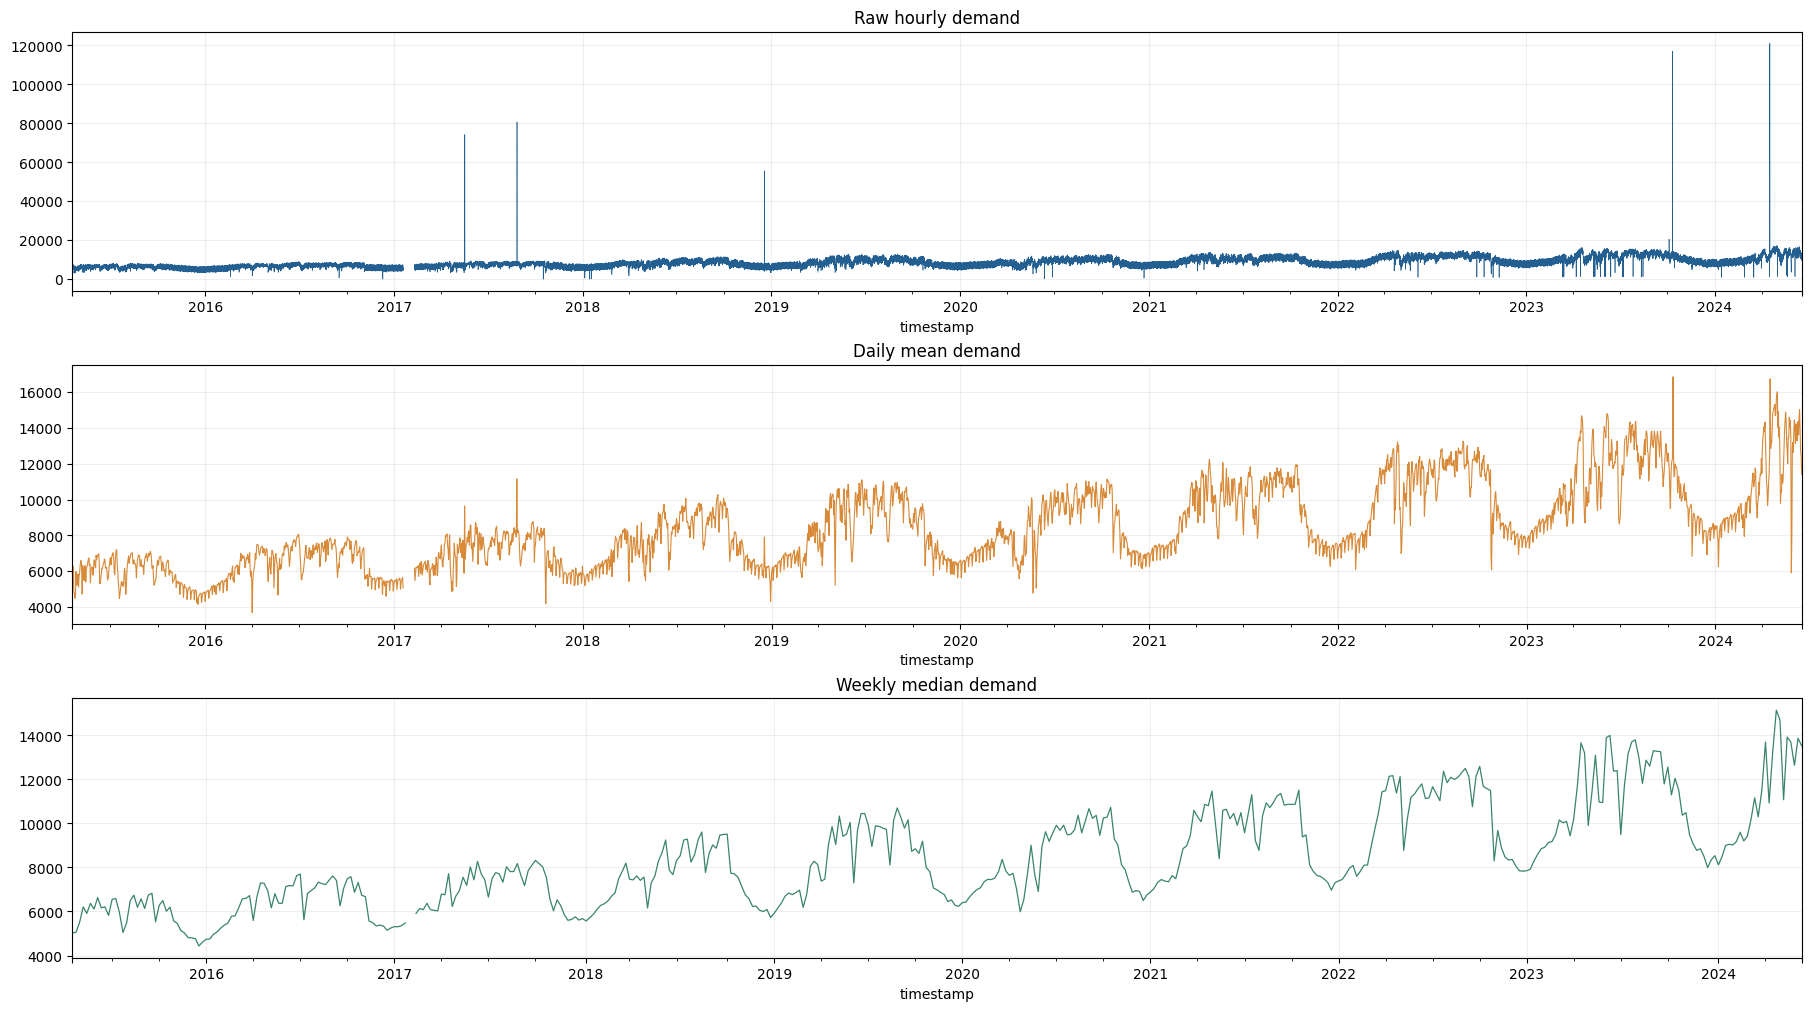

Missing target intervals: 222
Longest missing target interval (hours): 517
Negative demand values: 0 nonpositive: 0


In [ ]:
target_raw = hourly["demand_mw"].astype(float).copy()
coverage = pd.DataFrame({
    "non_missing": hourly.notna().sum(),
    "missing_pct": 100 * hourly.isna().mean(),
    "first_available": [hourly[c].first_valid_index() for c in hourly.columns],
    "last_available": [hourly[c].last_valid_index() for c in hourly.columns],
    "unique_values": [hourly[c].nunique(dropna=True) for c in hourly.columns],
}).sort_values("missing_pct", ascending=False)
coverage.to_csv(OUTDIR / "column_coverage_audit.csv")
display(target_raw.describe(percentiles=[.001,.005,.01,.05,.5,.95,.99,.995,.999]).to_frame("demand_mw"))
display(coverage)

fig, ax = plt.subplots(3, 1, figsize=(18, 10), constrained_layout=True)
target_raw.plot(ax=ax[0], lw=.45, color="#245f91", title="Raw hourly demand")
target_raw.resample("D").mean().plot(ax=ax[1], lw=.8, color="#d88a38", title="Daily mean demand")
target_raw.resample("W").median().plot(ax=ax[2], lw=.9, color="#39846a", title="Weekly median demand")
for a in ax: a.grid(alpha=.2)
plt.show()

# Missing-interval report. Target labels are never interpolated.
missing_mask = target_raw.isna().to_numpy()
intervals=[]; start=None
for i, flag in enumerate(missing_mask):
    if flag and start is None: start=i
    if (not flag or i==len(missing_mask)-1) and start is not None:
        end = i-1 if not flag else i
        intervals.append({"start": hourly.index[start], "end": hourly.index[end], "hours": end-start+1})
        start=None
missing_intervals = pd.DataFrame(intervals)
missing_intervals.to_csv(OUTDIR / "missing_target_intervals.csv", index=False)
print("Missing target intervals:", len(missing_intervals))
print("Longest missing target interval (hours):", int(missing_intervals.hours.max()) if len(missing_intervals) else 0)
print("Negative demand values:", int((target_raw < 0).sum()), "nonpositive:", int((target_raw <= 0).sum()))

## 4 · Causal gross-error detection (preserve raw observations)

High candidates: 5
Low-collapse candidates: 0
Persistent regime candidates preserved: 0
Masked from model training / historical lag inputs: 5


,demand_raw_mw,past_hour_of_week_median,past_robust_scale,robust_z,ratio_to_past_seasonal_median,high_spike_candidate,low_collapse_candidate,nonpositive_candidate,persistent_regime_candidate,gross_error_candidate,masked_for_model
timestamp,,,,,,,,,,,
2017-05-17 12:00:00,74223.0,6444.5,927.538918,73.073484,11.517263,True,False,False,False,True,True
2017-08-26 15:00:00,80689.0,6372.5,1438.843588,51.650159,12.662064,True,False,False,False,True,True
2018-12-18 08:00:00,55639.0,6718.5,1146.960712,42.652289,8.281462,True,False,False,False,True,True
2023-10-11 03:00:00,117000.0,10264.0,3727.575982,28.634158,11.399065,True,False,False,False,True,True
2024-04-16 07:00:00,121000.0,9698.5,1639.547813,67.885486,12.476156,True,False,False,False,True,True


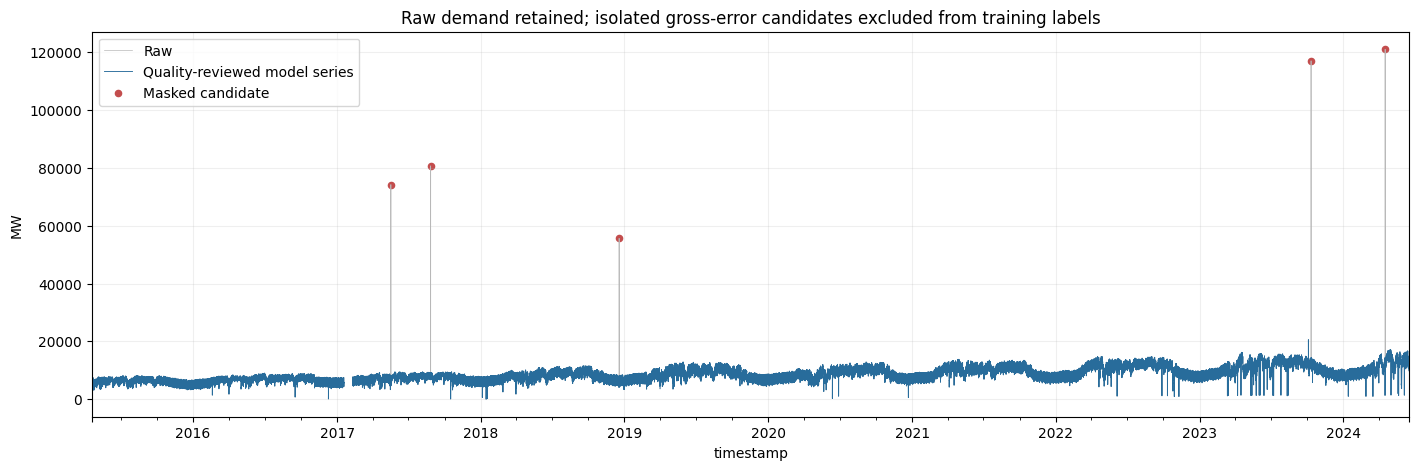

Past-only input still missing: 0


In [ ]:
def causal_target_quality(y: pd.Series):
    """Flag isolated extreme observations using only information available at or before each timestamp.

    A candidate must be an extreme ratio AND a large robust deviation from prior same-hour-of-week values.
    A sustained same-direction run is treated as a possible regime shift after PERSISTENCE_HOURS; it is
    flagged for review but not automatically masked. Raw values are never overwritten.
    """
    y = y.astype(float)
    slot = pd.Series(y.index.dayofweek * 24 + y.index.hour, index=y.index)
    med = y.groupby(slot).transform(lambda s: s.shift(1).rolling(SEASONAL_HISTORY_WEEKS, min_periods=MIN_SEASONAL_PEERS).median())
    q25 = y.groupby(slot).transform(lambda s: s.shift(1).rolling(SEASONAL_HISTORY_WEEKS, min_periods=MIN_SEASONAL_PEERS).quantile(.25))
    q75 = y.groupby(slot).transform(lambda s: s.shift(1).rolling(SEASONAL_HISTORY_WEEKS, min_periods=MIN_SEASONAL_PEERS).quantile(.75))
    past_global = y.expanding(min_periods=24*14).median().shift(1)
    med = med.fillna(past_global)
    scale = ((q75-q25)/1.349).fillna((y-past_global).abs().expanding(min_periods=24*14).median().shift(1)*1.4826)
    scale = scale.clip(lower=np.maximum(1.0, med.abs()*0.002))
    z = (y-med)/scale
    ratio = y/med.replace(0,np.nan)
    high = y.notna() & med.notna() & (ratio >= EXTREME_HIGH_RATIO) & (z >= ROBUST_Z_THRESHOLD)
    low = y.notna() & med.notna() & (ratio <= EXTREME_LOW_RATIO) & (z <= -ROBUST_Z_THRESHOLD)
    nonpositive = y.notna() & (y <= 0)
    code = np.where(high, 1, np.where(low, -1, 0))
    persistent = np.zeros(len(y), dtype=bool)
    run = 0; prev = 0
    for i, c in enumerate(code):
        if c != 0 and c == prev: run += 1
        elif c != 0: run = 1
        else: run = 0
        if c != 0 and run >= PERSISTENCE_HOURS: persistent[i] = True
        prev = c
    candidate = high | low | nonpositive
    masked = nonpositive | ((high | low) & ~persistent)
    audit = pd.DataFrame({
        "demand_raw_mw": y, "past_hour_of_week_median": med, "past_robust_scale": scale,
        "robust_z": z, "ratio_to_past_seasonal_median": ratio,
        "high_spike_candidate": high, "low_collapse_candidate": low,
        "nonpositive_candidate": nonpositive, "persistent_regime_candidate": persistent,
        "gross_error_candidate": candidate, "masked_for_model": masked,
    }, index=y.index)
    cleaned = y.copy()
    cleaned.loc[masked] = np.nan
    return audit, cleaned

anomaly_audit, target_model = causal_target_quality(target_raw)
anomaly_audit.to_csv(OUTDIR / "data_anomaly_audit.csv")
print("High candidates:", int(anomaly_audit.high_spike_candidate.sum()))
print("Low-collapse candidates:", int(anomaly_audit.low_collapse_candidate.sum()))
print("Persistent regime candidates preserved:", int(anomaly_audit.persistent_regime_candidate.sum()))
print("Masked from model training / historical lag inputs:", int(anomaly_audit.masked_for_model.sum()))
display(anomaly_audit.loc[anomaly_audit.gross_error_candidate | anomaly_audit.persistent_regime_candidate].head(100))

fig, ax = plt.subplots(figsize=(17, 5))
target_raw.plot(ax=ax, lw=.5, color="0.72", label="Raw")
target_model.plot(ax=ax, lw=.65, color="#286c9b", label="Quality-reviewed model series")
flags = anomaly_audit.masked_for_model
ax.scatter(target_raw.index[flags], target_raw.loc[flags], s=20, color="#c34d4d", label="Masked candidate")
ax.set_title("Raw demand retained; isolated gross-error candidates excluded from training labels")
ax.set_ylabel("MW"); ax.grid(alpha=.2); ax.legend(); plt.show()

# Past-only feature input imputation. No backward-fill or interpolation.
y_input = target_model.ffill(limit=3)
recent_median = target_model.shift(1).rolling(168, min_periods=24).median()
weekly_lag = target_model.shift(168)
seasonal_fallback = anomaly_audit["past_hour_of_week_median"]
expanding_fallback = target_model.expanding(min_periods=24*14).median().shift(1)
y_input = y_input.fillna(recent_median).fillna(weekly_lag).fillna(seasonal_fallback).fillna(expanding_fallback)
y_missing = target_model.isna().astype(float)

# If the latest context is still largely absent, tree models can fall back to rolling/calendar features;
# neural windows will be gated by an explicit missingness threshold.
print("Past-only input still missing:", int(y_input.isna().sum()))
assert y_input.index.equals(target_raw.index)
assert not y_input.loc[y_input.notna()].isna().any()

## 5 · Build point-in-time features for the 24 forecast horizons

In [ ]:
ORIGIN_LAGS = [0,1,2,3,6,12,24,48,72,168,336,504,672,1344]
TARGET_ALIGNED_LAGS = [24,48,72,168,336,504,672,1344]
ROLL_WINDOWS = [6,24,72,168,336,672,1344]

# Use operational values only as observed at/before the issue origin. Drop columns with very sparse coverage.
OP_CANDIDATES = [c for c in [
    "generation_mw", "load_shedding", "gas", "liquid_fuel", "coal", "hydro", "solar", "wind",
    "india_bheramara_hvdc", "india_tripura", "india_adani", "nepal"
] if c in hourly.columns]
OP_COV = hourly[OP_CANDIDATES].notna().mean() if OP_CANDIDATES else pd.Series(dtype=float)
# Keep the schema fixed from the published column list, not from full-history availability.
# Per-fold `usable_features()` decides from that fold's training rows whether a covariate is usable.
# This prevents a late-starting column from being selected merely because future history contains it.
OP_FEATURES = OP_CANDIDATES.copy() if USE_OPERATIONAL_CONTEXT else []
print("Operational history candidates:", OP_FEATURES)
print("Full-history coverage (audit only; not used to select features):")
if len(OP_COV): display(OP_COV.sort_values(ascending=False).to_frame("coverage"))

class DayAheadFeatureBuilder:
    def __init__(self, frame, y_raw, y_model, y_input, y_missing, covariate_names):
        self.frame = frame
        self.index = frame.index
        self.n = len(frame)
        self.y_raw = np.asarray(y_raw, dtype=float)
        self.y_model = np.asarray(y_model, dtype=float)
        self.y_input = np.asarray(y_input, dtype=float)
        self.y_missing = np.asarray(y_missing, dtype=float)
        self.covariate_names = list(covariate_names)
        self.cov = {c: frame[c].to_numpy(dtype=float) for c in self.covariate_names}
        if len(self.index) != self.n or not self.index.is_monotonic_increasing or self.index.has_duplicates:
            raise ValueError("Feature builder requires a sorted unique hourly index.")

    @staticmethod
    def safe(arr, pos):
        if pos < 0 or pos >= len(arr): return np.nan
        v = arr[pos]
        return float(v) if np.isfinite(v) else np.nan

    def build(self, origin_pos, include_labels=True):
        o = int(origin_pos); origin_ts = self.index[o]
        if origin_ts.hour != 23 or origin_ts.minute != 0:
            raise ValueError(f"Day-ahead origin must be 23:00, received {origin_ts}.")
        start = max(0, o-24*60+1)
        recent_missing = self.y_missing[start:o+1]
        valid_rev = np.flatnonzero(self.y_missing[start:o+1][::-1] < 0.5)
        missing_age = float(valid_rev[0]) if len(valid_rev) else float(o-start+1)
        base = {
            "origin_hour": origin_ts.hour, "origin_dow": origin_ts.dayofweek,
            "origin_month": origin_ts.month, "elapsed_days": float((origin_ts-self.index[0]).total_seconds()/86400),
            "origin_demand_missing_age_hours": missing_age,
        }
        for lag in ORIGIN_LAGS:
            val = self.safe(self.y_input, o-lag)
            base[f"origin_demand_lag_{lag}"] = val
            base[f"origin_demand_lag_{lag}_missing"] = float(not np.isfinite(self.safe(self.y_model,o-lag)))
        for w in ROLL_WINDOWS:
            a=max(0,o-w+1)
            raw=self.y_model[a:o+1]
            inp=self.y_input[a:o+1]
            good=inp[np.isfinite(inp)]
            base[f"origin_demand_roll_coverage_{w}"] = float(np.isfinite(raw).mean()) if len(raw) else 0.0
            for stat, fn in [("mean",np.mean),("std",np.std),("median",np.median),("min",np.min),("max",np.max),("q10",lambda z:np.quantile(z,.10)),("q90",lambda z:np.quantile(z,.90))]:
                base[f"origin_demand_roll_{stat}_{w}"] = float(fn(good)) if len(good) else np.nan
        # Trend and volatility ratios from non-overlapping recent windows.
        for w in [24,168,672]:
            a=max(0,o-2*w+1); b=max(0,o-w+1)
            prev=self.y_input[a:b]; curr=self.y_input[b:o+1]
            p=prev[np.isfinite(prev)]; c=curr[np.isfinite(curr)]
            base[f"demand_mean_change_{w}"] = float(np.mean(c)-np.mean(p)) if len(c) and len(p) else np.nan
            base[f"demand_std_ratio_{w}"] = float((np.std(c)+1e-6)/(np.std(p)+1e-6)) if len(c)>1 and len(p)>1 else np.nan
        # Historical operational variables: all windows end at the origin, never at the target timestamp.
        context={}
        for col, arr in self.cov.items():
            context[f"ctx_{col}_at_origin"] = self.safe(arr,o)
            for lag in [24,168,672]: context[f"ctx_{col}_lag_{lag}"] = self.safe(arr,o-lag)
            for w in [24,168,672]:
                a=max(0,o-w+1); z=arr[a:o+1]; good=z[np.isfinite(z)]
                context[f"ctx_{col}_mean_{w}"] = float(np.mean(good)) if len(good) else np.nan
                context[f"ctx_{col}_std_{w}"] = float(np.std(good)) if len(good)>1 else np.nan
                context[f"ctx_{col}_coverage_{w}"] = float(np.isfinite(z).mean()) if len(z) else 0.0
            valid=np.flatnonzero(np.isfinite(arr[:o+1]))
            context[f"ctx_{col}_age_hours"] = float(o-valid[-1]) if len(valid) else float(24*365*20)
        rows=[]
        for h in range(1,25):
            target_pos=o+h
            if include_labels and target_pos>=self.n: continue
            target_ts=origin_ts+pd.Timedelta(hours=h)
            cal={
                "horizon":h,"target_hour":target_ts.hour,"target_dow":target_ts.dayofweek,
                "target_month":target_ts.month,"target_day_of_year":target_ts.dayofyear,
                "target_is_weekend":int(target_ts.dayofweek>=5),
                "target_hour_sin":np.sin(2*np.pi*target_ts.hour/24),
                "target_hour_cos":np.cos(2*np.pi*target_ts.hour/24),
                "target_dow_sin":np.sin(2*np.pi*target_ts.dayofweek/7),
                "target_dow_cos":np.cos(2*np.pi*target_ts.dayofweek/7),
                "target_year_sin":np.sin(2*np.pi*target_ts.dayofyear/365.25),
                "target_year_cos":np.cos(2*np.pi*target_ts.dayofyear/365.25),
                "target_month_sin":np.sin(2*np.pi*(target_ts.month-1)/12),
                "target_month_cos":np.cos(2*np.pi*(target_ts.month-1)/12),
                "target_hour_dow":target_ts.hour+24*target_ts.dayofweek,
            }
            row={**base,**context,**cal}
            for lag in TARGET_ALIGNED_LAGS:
                lp=target_pos-lag
                if lp>o: raise AssertionError(f"Leakage: target-aligned lag {lag} reaches beyond origin.")
                row[f"target_hour_lag_{lag}"] = self.safe(self.y_input,lp)
                row[f"target_hour_lag_{lag}_missing"] = float(not np.isfinite(self.safe(self.y_model,lp)))
            row["origin_ts"]=origin_ts; row["target_ts"]=target_ts; row["horizon"]=h
            if include_labels:
                row["y_raw"]=self.y_raw[target_pos]
                row["y"]=self.y_model[target_pos]
                row["label_masked"]=bool(np.isnan(self.y_model[target_pos]) and np.isfinite(self.y_raw[target_pos]))
                row["label_observed"]=bool(np.isfinite(self.y_raw[target_pos]))
            else:
                row["y_raw"]=np.nan; row["y"]=np.nan; row["label_masked"]=False; row["label_observed"]=False
            rows.append(row)
        return rows

builder = DayAheadFeatureBuilder(hourly,target_raw,target_model,y_input,y_missing,OP_FEATURES)
origin_positions=[i for i,t in enumerate(hourly.index) if t.hour==23 and i>=24*28]
feature_rows=[]
for k,pos in enumerate(origin_positions):
    feature_rows.extend(builder.build(pos,include_labels=True))
    if (k+1)%500==0: print(f"Built {k+1:,}/{len(origin_positions):,} daily origins")
samples=pd.DataFrame(feature_rows)
META_COLS={"origin_ts","target_ts","horizon","y","y_raw","label_masked","label_observed"}
DEMAND_FEATURES=[c for c in samples.columns if c not in META_COLS and not c.startswith("ctx_")]
CONTEXT_FEATURES=DEMAND_FEATURES+[c for c in samples.columns if c.startswith("ctx_")]
print("Supervised rows:",samples.shape)
print("Daily origins:",samples.origin_ts.nunique())
print("Demand features:",len(DEMAND_FEATURES),"Context features:",len(CONTEXT_FEATURES))
print("Trainable labels:",int(samples.y.notna().sum()),"Raw observed labels:",int(samples.y_raw.notna().sum()))

Operational history candidates: ['generation_mw', 'load_shedding', 'gas', 'liquid_fuel', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'india_tripura', 'india_adani', 'nepal']
Full-history coverage (audit only; not used to select features):


,coverage
generation_mw,0.986991
load_shedding,0.986991
gas,0.986991
liquid_fuel,0.986991
coal,0.986991
hydro,0.986991
india_tripura,0.986991
india_bheramara_hvdc,0.986991
solar,0.731576
wind,0.113858


Built 500/3,319 daily origins
Built 1,000/3,319 daily origins
Built 1,500/3,319 daily origins
Built 2,000/3,319 daily origins
Built 2,500/3,319 daily origins
Built 3,000/3,319 daily origins
Supervised rows: (79632, 300)
Daily origins: 3318
Demand features: 125 Context features: 293
Trainable labels: 78669 Raw observed labels: 78674


## 6 · Leakage and integrity stress tests

In [ ]:
# 1) Future perturbation: features for origin O must not change if any observation after O changes.
valid_positions=[p for p in origin_positions if p+24 < len(hourly)]
if not valid_positions: raise RuntimeError("No forecast origins available for causality tests.")
test_pos=valid_positions[-min(10,len(valid_positions))]
base_rows=builder.build(test_pos,include_labels=False)

# Clone builder with deliberately corrupted future target and operational values.
frame_perturbed=hourly.copy()
cut=test_pos+1
for c in frame_perturbed.columns:
    if pd.api.types.is_numeric_dtype(frame_perturbed[c]):
        frame_perturbed.iloc[cut:,frame_perturbed.columns.get_loc(c)] = frame_perturbed.iloc[cut:,frame_perturbed.columns.get_loc(c)].fillna(0)*19+12345
raw_p=target_raw.copy(); model_p=target_model.copy(); input_p=y_input.copy(); missing_p=y_missing.copy()
raw_p.iloc[cut:]=raw_p.iloc[cut:].fillna(0)*19+777
model_p.iloc[cut:]=model_p.iloc[cut:].fillna(0)*19+888
input_p.iloc[cut:]=input_p.iloc[cut:].fillna(0)*19+999
perturbed_builder=DayAheadFeatureBuilder(frame_perturbed,raw_p,model_p,input_p,missing_p,OP_FEATURES)
perturbed_rows=perturbed_builder.build(test_pos,include_labels=False)
feature_names=[c for c in base_rows[0] if c not in {"origin_ts","target_ts","y","y_raw","label_masked","label_observed"}]
for ra,rb in zip(base_rows,perturbed_rows):
    for c in feature_names:
        a,b=ra[c],rb[c]
        if pd.isna(a) and pd.isna(b): continue
        if isinstance(a,(float,int,np.number)) and isinstance(b,(float,int,np.number)):
            assert np.isclose(a,b,equal_nan=True),f"Future leakage in {c}"
        else: assert a==b,f"Future leakage in {c}"

# 2) Every one of the 24 target-aligned lags must be at or before the issue origin.
for row in base_rows:
    for lag in TARGET_ALIGNED_LAGS:
        assert pd.Timestamp(row["target_ts"])-pd.Timedelta(hours=lag) <= pd.Timestamp(row["origin_ts"])

# 3) No sample target can precede or equal its own origin.
assert (samples.target_ts > samples.origin_ts).all()
assert ((samples.target_ts-samples.origin_ts).dt.total_seconds()/3600 == samples.horizon).all()

# 4) Cutoff invariant: the modelling table contains no record after the exact requested origin.
assert hourly.index.max()==forecast_origin and not (hourly.index>forecast_origin).any()

# 5) Past-only imputation invariant: no backfill/interpolation was used; values before first valid reading remain missing.
first_valid=target_model.first_valid_index()
if first_valid is not None:
    assert y_input.loc[:first_valid].notna().sum() <= 1

print("PASS 1 — perturbing all future target/covariate values leaves origin features unchanged")
print("PASS 2 — all target-aligned lags are observable at issue time")
print("PASS 3 — target timestamps are exactly horizons 1..24 after each origin")
print("PASS 4 — hidden ISO date is strictly cut off at previous-day 23:00")
print("PASS 5 — no future/backward imputation")

PASS 1 — perturbing all future target/covariate values leaves origin features unchanged
PASS 2 — all target-aligned lags are observable at issue time
PASS 3 — target timestamps are exactly horizons 1..24 after each origin
PASS 4 — hidden ISO date is strictly cut off at previous-day 23:00
PASS 5 — no future/backward imputation


## 7 · Rolling-origin splits (separate CV, tuning and final holdout)

In [ ]:
origin_table=samples.groupby("origin_ts").agg(
    raw_targets=("label_observed","sum"), usable_targets=("y",lambda s:int(s.notna().sum()))
).sort_index()
eligible_origins=list(origin_table.index)

# Reserve recent windows in chronological order: outer CV -> tuning -> final holdout.
if len(eligible_origins) < MIN_TRAIN_DAYS + CV_FOLDS*CV_DAYS + TUNE_DAYS + HOLDOUT_DAYS:
    raise ValueError(f"Insufficient usable daily origins ({len(eligible_origins)}). Need more history or smaller explicitly justified windows.")
holdout_origins=eligible_origins[-HOLDOUT_DAYS:]
pre_holdout=eligible_origins[:-HOLDOUT_DAYS]
tune_origins=pre_holdout[-TUNE_DAYS:]
pre_tune=pre_holdout[:-TUNE_DAYS]

last_start=len(pre_tune)-CV_DAYS
if last_start<=MIN_TRAIN_DAYS: raise ValueError("Not enough pre-tuning history for configured rolling folds.")
starts=np.linspace(MIN_TRAIN_DAYS,last_start,CV_FOLDS).round().astype(int)
folds=[]; used=set()
for st in starts:
    v=pre_tune[st:st+CV_DAYS]
    if len(v)!=CV_DAYS or any(o in used for o in v): continue
    folds.append(v); used.update(v)
if len(folds)<3: raise ValueError("Could not construct at least three non-overlapping rolling validation windows.")

print("History origins:",len(eligible_origins))
for i,f in enumerate(folds,1): print(f"CV {i}: {f[0]} -> {f[-1]} ({len(f)} forecast origins)")
print("Tuning block:",tune_origins[0],"->",tune_origins[-1])
print("Untouched final holdout:",holdout_origins[0],"->",holdout_origins[-1])

History origins: 3318
CV 1: 2017-05-16 23:00:00 -> 2017-05-29 23:00:00 (14 forecast origins)
CV 2: 2019-02-06 23:00:00 -> 2019-02-19 23:00:00 (14 forecast origins)
CV 3: 2020-10-29 23:00:00 -> 2020-11-11 23:00:00 (14 forecast origins)
CV 4: 2022-07-23 23:00:00 -> 2022-08-05 23:00:00 (14 forecast origins)
CV 5: 2024-04-14 23:00:00 -> 2024-04-27 23:00:00 (14 forecast origins)
Tuning block: 2024-04-28 23:00:00 -> 2024-05-18 23:00:00
Untouched final holdout: 2024-05-19 23:00:00 -> 2024-06-15 23:00:00


## 8 · Metrics and seasonal baselines

In [ ]:
def metric_pack(y_true,y_pred):
    yt=np.asarray(y_true,dtype=float); yp=np.asarray(y_pred,dtype=float)
    m=np.isfinite(yt)&np.isfinite(yp); yt=yt[m]; yp=yp[m]
    if len(yt)==0: return {"n":0,"MAE":np.nan,"RMSE":np.nan,"WAPE_pct":np.nan,"sMAPE_pct":np.nan,"Bias_MW":np.nan}
    e=yp-yt; den=np.sum(np.abs(yt))
    return {"n":int(len(yt)),"MAE":float(np.mean(np.abs(e))),"RMSE":float(np.sqrt(np.mean(e**2))),
            "WAPE_pct":float(100*np.sum(np.abs(e))/den) if den>0 else np.nan,
            "sMAPE_pct":float(100*np.mean(2*np.abs(e)/np.maximum(np.abs(yt)+np.abs(yp),1e-9))),
            "Bias_MW":float(np.mean(e))}


def add_baseline_predictions(df):
    z=df.copy()
    d=z["target_hour_lag_24"].astype(float)
    w=z["target_hour_lag_168"].astype(float)
    fallback=z["origin_demand_roll_mean_24"].astype(float)
    fallback=fallback.fillna(z["origin_demand_roll_mean_168"]).fillna(z["origin_demand_roll_mean_672"])
    d=d.where(np.isfinite(d),w)
    d=d.where(np.isfinite(d),fallback)
    w=w.where(np.isfinite(w),d)
    w=w.where(np.isfinite(w),fallback)
    z["pred_seasonal_day"]=d
    z["pred_seasonal_week"]=w
    z["pred_day_week_mean"]=0.5*d+0.5*w
    return z

base_samples=add_baseline_predictions(samples)
for col in ["pred_seasonal_day","pred_seasonal_week","pred_day_week_mean"]:
    print(col,metric_pack(base_samples.y,base_samples[col]))

pred_seasonal_day {'n': 78669, 'MAE': 539.8535827327156, 'RMSE': 881.9482638225537, 'WAPE_pct': 6.367606525113088, 'sMAPE_pct': 6.748344763614983, 'Bias_MW': -0.9747104958751224}
pred_seasonal_week {'n': 78669, 'MAE': 791.7311139076384, 'RMSE': 1243.3967152449907, 'WAPE_pct': 9.338517643124305, 'sMAPE_pct': 9.405950396838742, 'Bias_MW': -13.07855699195363}
pred_day_week_mean {'n': 78669, 'MAE': 553.1112541153441, 'RMSE': 868.1785516934684, 'WAPE_pct': 6.523981582173007, 'sMAPE_pct': 6.665046969422632, 'Bias_MW': -7.026633743914376}


## 9 · Tree models with temporal early stopping and full-data refit

In [ ]:
N_JOBS = -1
BASE_LGB = dict(
    objective="regression_l1", n_estimators=2200, learning_rate=0.025,
    num_leaves=31, max_depth=-1, min_child_samples=45,
    subsample=0.85, subsample_freq=1, colsample_bytree=0.85,
    reg_alpha=0.2, reg_lambda=8.0, random_state=SEED,
    n_jobs=N_JOBS, verbosity=-1, deterministic=True, force_col_wise=True
)
BASE_CAT = dict(
    iterations=1800, depth=7, learning_rate=0.03, loss_function="MAE",
    eval_metric="MAE", l2_leaf_reg=8.0, random_seed=SEED,
    verbose=False, allow_writing_files=False, thread_count=N_JOBS,
    random_strength=0.5
)
META_COLS={"origin_ts","target_ts","horizon","y","y_raw","label_masked","label_observed","pred_seasonal_day","pred_seasonal_week","pred_day_week_mean"}

def usable_features(train_df, feature_kind):
    feats=DEMAND_FEATURES if feature_kind=="demand" else CONTEXT_FEATURES
    return [c for c in feats if c in train_df and train_df[c].notna().mean() >= MIN_COVARIATE_COVERAGE
            and train_df[c].nunique(dropna=True)>1]


def fit_tree(algo, train_df, feature_kind="demand", params=None, early_stop=True):
    """Temporal inner early stop, then refit on every eligible training row."""
    train=train_df.loc[train_df.y.notna()].sort_values(["origin_ts","horizon"]).copy()
    feats=usable_features(train,feature_kind)
    if len(train)<500 or not feats: raise ValueError("Insufficient labelled rows/features for tree fitting.")
    p=(BASE_LGB if algo=="lgbm" else BASE_CAT).copy(); p.update(params or {})
    best_iter=int(p.get("n_estimators",p.get("iterations",1600)))
    if early_stop:
        origins=sorted(train.origin_ts.unique())
        n_inner=min(14,max(7,len(origins)//8))
        if len(origins)>n_inner+90:
            inner_val_origins=origins[-n_inner:]
            inner_start=inner_val_origins[0]
            itr=train.loc[train.target_ts<=inner_start]
            iva=train.loc[train.origin_ts.isin(inner_val_origins)&train.y.notna()]
            if len(itr)>=400 and len(iva)>=100:
                Xtr=itr[feats].replace([np.inf,-np.inf],np.nan); ytr=itr.y.astype(float)
                Xva=iva[feats].replace([np.inf,-np.inf],np.nan); yva=iva.y.astype(float)
                if algo=="lgbm":
                    probe=LGBMRegressor(**p)
                    probe.fit(Xtr,ytr,eval_set=[(Xva,yva)],eval_metric="l1",
                              callbacks=[early_stopping(120,verbose=False),log_evaluation(0)])
                    best_iter=int(probe.best_iteration_ or p.get("n_estimators",2200))
                else:
                    probe=CatBoostRegressor(**p)
                    probe.fit(Xtr,ytr,eval_set=(Xva,yva),early_stopping_rounds=120,verbose=False,use_best_model=True)
                    bi=probe.get_best_iteration()
                    best_iter=int(bi+1 if bi is not None and bi>=0 else p.get("iterations",1800))
                del probe
    if algo=="lgbm":
        final_params=p.copy(); final_params["n_estimators"]=max(100,best_iter)
        model=LGBMRegressor(**final_params)
    elif algo=="cat":
        final_params=p.copy(); final_params["iterations"]=max(100,best_iter)
        model=CatBoostRegressor(**final_params)
    else: raise ValueError(algo)
    X=train[feats].replace([np.inf,-np.inf],np.nan); y=train.y.astype(float)
    model.fit(X,y)
    return model,feats,best_iter


def predict_tree(model, features, frame):
    X=frame[features].replace([np.inf,-np.inf],np.nan)
    p=np.asarray(model.predict(X),dtype=float)
    return np.maximum(p,0.0)

print("Tree estimators configured. All fitting rows are chronologically filtered at each forecast origin.")

Tree estimators configured. All fitting rows are chronologically filtered at each forecast origin.


## 10 · GPU neural challengers: DLinear and PatchTST

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

LOOKBACK=NEURAL_LOOKBACK

def make_neural_windows(origins, label_cutoff):
    X=[]; Y=[]; M=[]; kept=[]
    index=builder.index
    for o in origins:
        pos=index.get_indexer([o])[0]
        if pos<LOOKBACK-1: continue
        # Every input is strictly at/before o; all target labels must be <= cutoff.
        xa=pos-LOOKBACK+1; xb=pos+1
        xv=builder.y_input[xa:xb]
        mv=builder.y_missing[xa:xb]
        if len(xv)!=LOOKBACK or not np.isfinite(xv).all(): continue
        if float(np.mean(mv))>NEURAL_MAX_MISSING_FRACTION: continue
        yv=np.full(24,np.nan,dtype=np.float32)
        for h in range(1,25):
            t=pos+h
            if t<len(index) and index[t]<=label_cutoff:
                val=builder.y_model[t]
                if np.isfinite(val): yv[h-1]=float(val)
        mask=np.isfinite(yv)
        if mask.sum()<12: continue
        X.append(np.stack([xv.astype(np.float32),mv.astype(np.float32)],axis=-1))
        Y.append(np.nan_to_num(yv,nan=0.0)); M.append(mask.astype(np.float32)); kept.append(o)
    if not X:
        return np.empty((0,LOOKBACK,2),np.float32),np.empty((0,24),np.float32),np.empty((0,24),np.float32),[]
    return np.stack(X),np.stack(Y),np.stack(M),kept


class DLinear24(nn.Module):
    def __init__(self, lookback=LOOKBACK, horizon=24, kernel=25, dropout=.10):
        super().__init__(); self.kernel=kernel
        self.seasonal=nn.Linear(lookback,horizon); self.trend=nn.Linear(lookback,horizon)
        self.missing=nn.Linear(lookback,horizon,bias=False); self.drop=nn.Dropout(dropout)
    def forward(self,x):
        v=x[:,:,0]; miss=x[:,:,1].clamp(0,1); w=1-miss
        mu=(v*w).sum(1,keepdim=True)/w.sum(1,keepdim=True).clamp_min(1)
        var=(((v-mu)**2)*w).sum(1,keepdim=True)/w.sum(1,keepdim=True).clamp_min(1)
        sd=torch.sqrt(var.clamp_min(1e-4)).clamp_min(1)
        z=(v-mu)/sd; pad=(self.kernel-1)//2
        trend=F.avg_pool1d(F.pad(z.unsqueeze(1),(pad,pad),mode="replicate"),self.kernel,1).squeeze(1)
        seasonal=z-trend
        out=self.seasonal(self.drop(seasonal))+self.trend(self.drop(trend))+self.missing(miss)
        return out*sd+mu,mu,sd


class PatchTST24(nn.Module):
    def __init__(self,lookback=LOOKBACK,horizon=24,patch_len=PATCH_LEN,stride=PATCH_STRIDE,d_model=PATCH_D_MODEL,heads=PATCH_HEADS,layers=PATCH_LAYERS,dropout=PATCH_DROPOUT):
        super().__init__(); self.patch_len=patch_len; self.stride=stride
        self.n_patches=(lookback-patch_len)//stride+1
        self.proj=nn.Linear(patch_len*2,d_model)
        self.pos=nn.Parameter(torch.zeros(1,self.n_patches,d_model))
        enc=nn.TransformerEncoderLayer(d_model=d_model,nhead=heads,dim_feedforward=4*d_model,dropout=dropout,batch_first=True,activation="gelu",norm_first=True)
        self.encoder=nn.TransformerEncoder(enc,num_layers=layers,norm=nn.LayerNorm(d_model))
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(self.n_patches*d_model,256),nn.GELU(),nn.Dropout(dropout),nn.Linear(256,horizon))
        nn.init.trunc_normal_(self.pos,std=.02)
    def forward(self,x):
        v=x[:,:,0]; miss=x[:,:,1].clamp(0,1); w=1-miss
        mu=(v*w).sum(1,keepdim=True)/w.sum(1,keepdim=True).clamp_min(1)
        var=(((v-mu)**2)*w).sum(1,keepdim=True)/w.sum(1,keepdim=True).clamp_min(1)
        sd=torch.sqrt(var.clamp_min(1e-4)).clamp_min(1)
        z=torch.stack([(v-mu)/sd,miss],dim=-1)
        patches=z.unfold(1,self.patch_len,self.stride).permute(0,1,3,2).reshape(z.shape[0],self.n_patches,self.patch_len*2)
        h=self.encoder(self.proj(patches)+self.pos)
        return self.head(h)*sd+mu,mu,sd


def masked_huber(pred, target, mask, mu, sd):
    err=(pred-mu)/sd-(target-mu)/sd
    loss=F.smooth_l1_loss(err,torch.zeros_like(err),reduction="none",beta=.5)
    return (loss*mask).sum()/mask.sum().clamp_min(1)


def train_neural(name, train_origins, label_cutoff, max_epochs=NEURAL_MAX_EPOCHS, patience=NEURAL_PATIENCE, seed=SEED):
    X,Y,M,kept=make_neural_windows(train_origins,label_cutoff)
    if len(X)<150: raise ValueError(f"Only {len(X)} usable windows for {name}.")
    split=max(1,int(len(X)*.85))
    if len(X)-split<14: split=max(1,len(X)-14)
    if split<50: raise ValueError("Not enough chronological windows for stable neural early stopping.")
    if name=="patchtst": make_model=lambda:PatchTST24()
    elif name=="dlinear": make_model=lambda:DLinear24()
    else: raise ValueError(name)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    probe=make_model().to(DEVICE)
    opt=torch.optim.AdamW(probe.parameters(),lr=(2e-4 if name=="patchtst" else 7e-4),weight_decay=3e-4)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode="min",factor=.5,patience=3,min_lr=1e-6)
    trds=TensorDataset(torch.from_numpy(X[:split]),torch.from_numpy(Y[:split]),torch.from_numpy(M[:split]))
    loader=DataLoader(trds,batch_size=NEURAL_BATCH_SIZE,shuffle=True,drop_last=False,pin_memory=(DEVICE=="cuda"))
    xv=torch.from_numpy(X[split:]).to(DEVICE); yv=torch.from_numpy(Y[split:]).to(DEVICE); mv=torch.from_numpy(M[split:]).to(DEVICE)
    best=np.inf; best_epoch=1; wait=0; best_state=None
    for epoch in range(1,max_epochs+1):
        probe.train(); losses=[]
        for xb,yb,mb in loader:
            xb=xb.to(DEVICE,non_blocking=True); yb=yb.to(DEVICE,non_blocking=True); mb=mb.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            pred,mu,sd=probe(xb)
            loss=masked_huber(pred,yb,mb,mu,sd)
            loss.backward(); torch.nn.utils.clip_grad_norm_(probe.parameters(),1.0); opt.step()
            losses.append(float(loss.detach().cpu()))
        probe.eval()
        with torch.no_grad():
            pv,muv,sdv=probe(xv); vl=float(masked_huber(pv,yv,mv,muv,sdv).cpu())
        scheduler.step(vl)
        if vl<best-1e-5:
            best=vl; best_epoch=epoch; wait=0
            best_state={k:v.detach().cpu().clone() for k,v in probe.state_dict().items()}
        else: wait+=1
        if epoch%10==0: print(f"{name} epoch {epoch}/{max_epochs} train={np.mean(losses):.4f} val={vl:.4f} best={best:.4f}@{best_epoch}")
        if wait>=patience: break
    del probe, opt, loader, xv, yv, mv
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    # Critical improvement: refit on ALL eligible windows for the selected epoch count.
    torch.manual_seed(seed+1000)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed+1000)
    final_model=make_model().to(DEVICE)
    final_opt=torch.optim.AdamW(final_model.parameters(),lr=(2e-4 if name=="patchtst" else 7e-4),weight_decay=3e-4)
    allds=TensorDataset(torch.from_numpy(X),torch.from_numpy(Y),torch.from_numpy(M))
    allloader=DataLoader(allds,batch_size=NEURAL_BATCH_SIZE,shuffle=True,drop_last=False,pin_memory=(DEVICE=="cuda"))
    for ep in range(best_epoch):
        final_model.train()
        for xb,yb,mb in allloader:
            xb=xb.to(DEVICE,non_blocking=True); yb=yb.to(DEVICE,non_blocking=True); mb=mb.to(DEVICE,non_blocking=True)
            final_opt.zero_grad(set_to_none=True); pred,mu,sd=final_model(xb)
            loss=masked_huber(pred,yb,mb,mu,sd); loss.backward()
            torch.nn.utils.clip_grad_norm_(final_model.parameters(),1.0); final_opt.step()
    final_model.eval()
    del final_opt, allloader
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return final_model,best_epoch,{"windows":len(X),"train_windows_for_early_stop":split,"early_stop_windows":len(X)-split,"best_val_loss":best}


def predict_neural(model, origins):
    rows=[]; model.eval()
    with torch.no_grad():
        for o in origins:
            pos=builder.index.get_indexer([o])[0]
            if pos<LOOKBACK-1: continue
            a=pos-LOOKBACK+1; x=builder.y_input[a:pos+1]; m=builder.y_missing[a:pos+1]
            if len(x)!=LOOKBACK or not np.isfinite(x).all() or np.mean(m)>NEURAL_MAX_MISSING_FRACTION: continue
            xb=torch.from_numpy(np.stack([x.astype(np.float32),m.astype(np.float32)],axis=-1)[None]).to(DEVICE)
            p,_,_=model(xb); p=np.maximum(p.detach().cpu().numpy().reshape(-1),0)
            for h in range(1,25): rows.append({"origin_ts":o,"target_ts":o+pd.Timedelta(hours=h),"horizon":h,"y_pred":float(p[h-1])})
    return pd.DataFrame(rows)

print("Neural models ready on",DEVICE)

Neural models ready on cuda


## 11 · Optional Chronos-2 foundation-model challenger

In [ ]:
chronos_pipe=None
chronos_available=False
if RUN_CHRONOS2:
    try:
        try:
            from chronos import Chronos2Pipeline
        except Exception:
            subprocess.check_call([sys.executable,"-m","pip","install","-q","chronos-forecasting"])
            from chronos import Chronos2Pipeline
        chronos_pipe=Chronos2Pipeline.from_pretrained("amazon/chronos-2",device_map=DEVICE)
        chronos_available=True
        print("Chronos-2 loaded on",DEVICE)
    except Exception as e:
        print("Chronos-2 unavailable; supervised models continue:",type(e).__name__,str(e)[:800])


def chronos_predict(origin):
    if not chronos_available: raise RuntimeError("Chronos-2 not loaded.")
    pos=builder.index.get_indexer([origin])[0]
    hist=pd.Series(builder.y_input[:pos+1],index=builder.index[:pos+1]).tail(8192)
    if hist.isna().any() or len(hist)<24*28: raise ValueError("Chronos context is incomplete or shorter than 28 days.")
    context=pd.DataFrame({"series_id":"grid_demand","time":hist.index,"target":hist.values.astype(float)})
    pred=chronos_pipe.predict_df(context,prediction_length=24,quantile_levels=[0.1,0.5,0.9],id_column="series_id",timestamp_column="time",target="target")
    qmap={}
    for c in pred.columns:
        try: qmap[round(float(c),2)]=c
        except Exception: pass
    if not {0.1,0.5,0.9}.issubset(qmap): raise RuntimeError(f"Unexpected Chronos output columns: {pred.columns.tolist()}")
    z=pred.tail(24)
    if len(z)!=24: raise RuntimeError("Chronos did not return 24 future values.")
    return {q:z[qmap[q]].to_numpy(float) for q in [0.1,0.5,0.9]}

print("Chronos-2 available:",chronos_available)

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos-2 loaded on cuda
Chronos-2 available: True


## 12 · Run rolling-origin model comparison

In [14]:
cv_records=[]
MODEL_SPECS=[("lgbm_demand","lgbm","demand"),("lgbm_context","lgbm","context"),
             ("cat_demand","cat","demand"),("cat_context","cat","context")]

for fi, val_origins in enumerate(folds,1):
    val_start=val_origins[0]
    train_df=samples.loc[(samples.target_ts<=val_start)&samples.y.notna()].copy()
    val_df=samples.loc[samples.origin_ts.isin(val_origins)].copy().sort_values(["origin_ts","horizon"])
    print(f"\nCV fold {fi}: train={len(train_df):,} rows | val={len(val_df):,} rows | {val_origins[0]} -> {val_origins[-1]}")
    vb=add_baseline_predictions(val_df)
    for name,col in [("seasonal_day","pred_seasonal_day"),("seasonal_week","pred_seasonal_week"),("seasonal_blend","pred_day_week_mean")]:
        z=vb[["origin_ts","target_ts","horizon","y_raw","y","label_masked","label_observed",col]].copy().rename(columns={col:"y_pred"})
        z["fold"]=fi; z["model"]=name; cv_records.append(z)

    for name,algo,kind in MODEL_SPECS:
        try:
            model,feats,best_iter=fit_tree(algo,train_df,kind,early_stop=True)
            p=predict_tree(model,feats,val_df)
            z=val_df[["origin_ts","target_ts","horizon","y_raw","y","label_masked","label_observed"]].copy()
            z["y_pred"]=p; z["fold"]=fi; z["model"]=name; z["best_iteration"]=best_iter
            cv_records.append(z)
            print(name,metric_pack(z.y,z.y_pred))
            del model
        except Exception as e: print("Tree candidate skipped:",name,type(e).__name__,str(e)[:500])

    train_origins=[o for o in eligible_origins if o<val_start and o+pd.Timedelta(hours=24)<=val_start]
    for name,enabled in [("dlinear",RUN_DLINEAR),("patchtst",RUN_PATCHTST)]:
        if not enabled: continue
        try:
            model,best_epoch,info=train_neural(name,train_origins,label_cutoff=val_start,max_epochs=NEURAL_MAX_EPOCHS,patience=NEURAL_PATIENCE,seed=SEED+fi)
            pp=predict_neural(model,val_origins)
            z=val_df.merge(pp[["origin_ts","horizon","y_pred"]],on=["origin_ts","horizon"],how="inner")
            z["fold"]=fi; z["model"]=name; z["best_epoch"]=best_epoch
            cv_records.append(z[["origin_ts","target_ts","horizon","y_raw","y","label_masked","label_observed","y_pred","fold","model"]])
            print(name,"epoch",best_epoch,"windows",info["windows"],metric_pack(z.y,z.y_pred))
            del model
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        except Exception as e: print("Neural candidate skipped:",name,type(e).__name__,str(e)[:700])

    if chronos_available:
        ch=[]
        for o in val_origins:
            try:
                q=chronos_predict(o)
                for h in range(1,25): ch.append({"origin_ts":o,"target_ts":o+pd.Timedelta(hours=h),"horizon":h,"y_pred":max(0,float(q[0.5][h-1]))})
            except Exception as e: print("Chronos origin skipped:",o,type(e).__name__,str(e)[:250])
        if ch:
            z=pd.DataFrame(ch).merge(val_df[["origin_ts","target_ts","horizon","y_raw","y","label_masked","label_observed"]],on=["origin_ts","target_ts","horizon"],how="left")
            z["fold"]=fi; z["model"]="chronos2"; cv_records.append(z)
            print("chronos2",metric_pack(z.y,z.y_pred))
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

cv_predictions=pd.concat(cv_records,ignore_index=True)
cv_predictions.to_csv(OUTDIR/"rolling_cv_predictions.csv",index=False)
print("CV prediction rows:",len(cv_predictions))


CV fold 1: train=16,907 rows | val=336 rows | 2017-05-16 23:00:00 -> 2017-05-29 23:00:00
lgbm_demand {'n': 322, 'MAE': 551.7513518827573, 'RMSE': 718.2737508928531, 'WAPE_pct': 7.187505979594499, 'sMAPE_pct': 7.395136119151648, 'Bias_MW': -308.32061221850563}
lgbm_context {'n': 322, 'MAE': 632.2395157384346, 'RMSE': 795.2369861482449, 'WAPE_pct': 8.236002112907448, 'sMAPE_pct': 8.463991431164466, 'Bias_MW': -429.6735532541853}
cat_demand {'n': 322, 'MAE': 540.0966155763733, 'RMSE': 714.1940831412121, 'WAPE_pct': 7.035683085809308, 'sMAPE_pct': 7.221768848893484, 'Bias_MW': -303.79075468871685}
cat_context {'n': 322, 'MAE': 575.9887486136237, 'RMSE': 753.2976858191411, 'WAPE_pct': 7.503239567447899, 'sMAPE_pct': 7.715565973820605, 'Bias_MW': -357.230658528107}
dlinear epoch 10/70 train=0.1866 val=0.2718 best=0.2718@10
dlinear epoch 20/70 train=0.1476 val=0.2504 best=0.2504@20
dlinear epoch 30/70 train=0.1303 val=0.2388 best=0.2388@30
dlinear epoch 40/70 train=0.1179 val=0.2331 best=0.2

/tmp/ipykernel_1427/3854513073.py:59: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/70 train=0.1749 val=0.2659 best=0.2659@10
patchtst epoch 20/70 train=0.1116 val=0.2405 best=0.2405@20
patchtst epoch 30/70 train=0.0815 val=0.2324 best=0.2324@30
patchtst epoch 40/70 train=0.0624 val=0.2336 best=0.2324@30
patchtst epoch 30 windows 683 {'n': 322, 'MAE': 629.6926891255823, 'RMSE': 792.6848234341622, 'WAPE_pct': 8.202825336001686, 'sMAPE_pct': 8.684117601255448, 'Bias_MW': -454.6153496215062}
chronos2 {'n': 322, 'MAE': 427.24898856026783, 'RMSE': 652.1021155809094, 'WAPE_pct': 5.565649544081514, 'sMAPE_pct': 5.882972284046963, 'Bias_MW': -53.33822574970885}

CV fold 2: train=31,861 rows | val=336 rows | 2019-02-06 23:00:00 -> 2019-02-19 23:00:00
lgbm_demand {'n': 334, 'MAE': 186.17715905227962, 'RMSE': 299.4435195897011, 'WAPE_pct': 2.7261853949791024, 'sMAPE_pct': 2.7882269802153448, 'Bias_MW': -8.885422944345542}
lgbm_context {'n': 334, 'MAE': 181.95104604342472, 'RMSE': 287.346220512396, 'WAPE_pct': 2.6643025752985414, 'sMAPE_pct': 2.723260283327629, 

/tmp/ipykernel_1427/3854513073.py:59: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/70 train=0.1625 val=0.1105 best=0.1105@10
patchtst epoch 20/70 train=0.1094 val=0.1017 best=0.0967@17
patchtst epoch 30/70 train=0.0823 val=0.0986 best=0.0962@25
patchtst epoch 25 windows 1313 {'n': 334, 'MAE': 203.40731866345433, 'RMSE': 301.08472607147957, 'WAPE_pct': 2.9784859979330514, 'sMAPE_pct': 3.0373120737624593, 'Bias_MW': 52.67633531764596}
chronos2 {'n': 334, 'MAE': 166.11482796126498, 'RMSE': 278.65509688249654, 'WAPE_pct': 2.432413407652768, 'sMAPE_pct': 2.4859966603565655, 'Bias_MW': 4.772528185815868}

CV fold 3: train=46,903 rows | val=336 rows | 2020-10-29 23:00:00 -> 2020-11-11 23:00:00
lgbm_demand {'n': 336, 'MAE': 363.8806405197832, 'RMSE': 488.0023848686996, 'WAPE_pct': 4.361841319607509, 'sMAPE_pct': 4.283923759127488, 'Bias_MW': 236.2576723923382}
lgbm_context {'n': 336, 'MAE': 404.2832768877432, 'RMSE': 547.8493152985308, 'WAPE_pct': 4.846148174951918, 'sMAPE_pct': 4.736076776280707, 'Bias_MW': 300.3643332586672}
cat_demand {'n': 336, 'MAE': 3

/tmp/ipykernel_1427/3854513073.py:59: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/70 train=0.1443 val=0.1752 best=0.1752@10
patchtst epoch 20/70 train=0.1044 val=0.1645 best=0.1645@20
patchtst epoch 30/70 train=0.0845 val=0.1652 best=0.1618@25
patchtst epoch 25 windows 1944 {'n': 336, 'MAE': 431.1669921875, 'RMSE': 536.6277500702287, 'WAPE_pct': 5.168403571808262, 'sMAPE_pct': 5.264272211629187, 'Bias_MW': -4.95855712890625}
chronos2 {'n': 336, 'MAE': 272.0467776343936, 'RMSE': 395.61786248343344, 'WAPE_pct': 3.26102777508786, 'sMAPE_pct': 3.2005040234488433, 'Bias_MW': 53.359219505673366}

CV fold 4: train=62,047 rows | val=336 rows | 2022-07-23 23:00:00 -> 2022-08-05 23:00:00
lgbm_demand {'n': 336, 'MAE': 335.89378974329634, 'RMSE': 430.8652324923948, 'WAPE_pct': 2.798616549774806, 'sMAPE_pct': 2.796054049604932, 'Bias_MW': -91.27376070070238}
lgbm_context {'n': 336, 'MAE': 335.0655053037945, 'RMSE': 421.8156589618542, 'WAPE_pct': 2.7917154083691185, 'sMAPE_pct': 2.793208425451927, 'Bias_MW': -53.88049279306105}
cat_demand {'n': 336, 'MAE': 289.9

/tmp/ipykernel_1427/3854513073.py:59: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/70 train=0.1457 val=0.1377 best=0.1377@10
patchtst epoch 20/70 train=0.1091 val=0.1367 best=0.1338@18
patchtst epoch 18 windows 2576 {'n': 336, 'MAE': 351.27020844959077, 'RMSE': 454.51056093776367, 'WAPE_pct': 2.9267305583743397, 'sMAPE_pct': 2.9727114576246274, 'Bias_MW': -84.36923072451637}
chronos2 {'n': 336, 'MAE': 323.8687017531622, 'RMSE': 423.78170686641295, 'WAPE_pct': 2.698425324782504, 'sMAPE_pct': 2.707934135898375, 'Bias_MW': -58.223914736793155}

CV fold 5: train=77,159 rows | val=336 rows | 2024-04-14 23:00:00 -> 2024-04-27 23:00:00
lgbm_demand {'n': 335, 'MAE': 831.8124388513213, 'RMSE': 1142.9747664374631, 'WAPE_pct': 5.860673860577653, 'sMAPE_pct': 6.104461353055498, 'Bias_MW': -577.9149957736366}
lgbm_context {'n': 335, 'MAE': 850.5862226492454, 'RMSE': 1175.3572490948216, 'WAPE_pct': 5.992947698800811, 'sMAPE_pct': 6.224676522473202, 'Bias_MW': -585.2573762553694}
cat_demand {'n': 335, 'MAE': 870.3163504456384, 'RMSE': 1174.7898449557165, 'WAPE_pct

/tmp/ipykernel_1427/3854513073.py:59: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/70 train=0.1428 val=0.1618 best=0.1592@9
patchtst epoch 20/70 train=0.0989 val=0.1610 best=0.1549@13
patchtst epoch 13 windows 3207 {'n': 335, 'MAE': 676.6015683302239, 'RMSE': 1030.189923172839, 'WAPE_pct': 4.767109675607479, 'sMAPE_pct': 5.068807520684548, 'Bias_MW': -389.56073927238805}
chronos2 {'n': 335, 'MAE': 487.4381529850746, 'RMSE': 903.417033362192, 'WAPE_pct': 3.4343271492703527, 'sMAPE_pct': 3.7691752263431604, 'Bias_MW': 23.19306786380597}
CV prediction rows: 16800


## 13 · Fold-stability leaderboard and model selection

In [15]:
summary=[]
for name,g in cv_predictions.groupby("model"):
    rawm=metric_pack(g.y_raw,g.y_pred)
    clean=metric_pack(g.y,g.y_pred)
    fold_raw=[]; fold_clean=[]
    for f,fg in g.groupby("fold"):
        mr=metric_pack(fg.y_raw,fg.y_pred)
        mc=metric_pack(fg.y,fg.y_pred)
        if np.isfinite(mr["WAPE_pct"]): fold_raw.append(mr["WAPE_pct"])
        if np.isfinite(mc["WAPE_pct"]): fold_clean.append(mc["WAPE_pct"])
    baseline_keys=cv_predictions.loc[cv_predictions.model=="seasonal_day",["fold","origin_ts","target_ts","horizon","y_raw"]].drop_duplicates()
    baseline_n=int(baseline_keys.y_raw.notna().sum())
    scored=g.loc[g.y_raw.notna() & g.y_pred.notna(),["fold","origin_ts","target_ts","horizon"]].drop_duplicates()
    coverage_fraction=float(len(scored)/max(1,baseline_n))
    summary.append({
        "model":name,
        "raw_WAPE_pct":rawm["WAPE_pct"], "raw_MAE_MW":rawm["MAE"], "raw_RMSE_MW":rawm["RMSE"], "raw_Bias_MW":rawm["Bias_MW"],
        "quality_WAPE_pct":clean["WAPE_pct"], "quality_MAE_MW":clean["MAE"],
        "mean_fold_raw_WAPE_pct":float(np.mean(fold_raw)) if fold_raw else np.nan,
        "std_fold_raw_WAPE_pct":float(np.std(fold_raw)) if fold_raw else np.nan,
        "worst_fold_raw_WAPE_pct":float(np.max(fold_raw)) if fold_raw else np.nan,
        "mean_fold_quality_WAPE_pct":float(np.mean(fold_clean)) if fold_clean else np.nan,
        "folds_scored":len(fold_raw), "coverage_fraction":coverage_fraction, "n_raw":rawm["n"], "n_quality":clean["n"]
    })
leaderboard=pd.DataFrame(summary)
# Primary selection is based on raw observations because those are the actual observed system outcomes.
# Stability penalties reduce the chance of selecting a model that wins only on one favourable fold.
leaderboard["selection_score"]=(0.65*leaderboard.mean_fold_raw_WAPE_pct
    +0.25*leaderboard.std_fold_raw_WAPE_pct+0.10*leaderboard.worst_fold_raw_WAPE_pct)
leaderboard=leaderboard.sort_values(["selection_score","raw_WAPE_pct"])
leaderboard.to_csv(OUTDIR/"rolling_cv_leaderboard.csv",index=False)
display(leaderboard)

eligible_models=leaderboard.loc[(leaderboard.coverage_fraction>=0.98)&(leaderboard.folds_scored>=3)&leaderboard.selection_score.notna()]
if eligible_models.empty: raise RuntimeError("No candidate has adequate raw-label validation coverage; inspect gaps/model failures.")
selected_single=str(eligible_models.iloc[0].model)
print("Best single model by raw-fold stability score:",selected_single)

# A simple equal-weight top-two ensemble is accepted only on identical raw-label observations,
# with a material pooled gain and improvement on nearly every fold. No stacking weights use the holdout.
model_names=list(eligible_models.model)
ensemble_members=[]
if len(model_names)>=2:
    top2=model_names[:2]
    piv=cv_predictions.loc[cv_predictions.model.isin(top2)].pivot_table(
        index=["fold","origin_ts","target_ts","horizon","y","y_raw"],columns="model",values="y_pred",aggfunc="first").dropna(subset=top2)
    if len(piv)>=500:
        raw_y=piv.index.get_level_values("y_raw")
        blend=(piv[top2[0]].to_numpy()+piv[top2[1]].to_numpy())/2
        blend_metric=metric_pack(raw_y,blend)
        best_g=piv.reset_index()
        one_a=metric_pack(best_g.y_raw,best_g[top2[0]])["WAPE_pct"]
        one_b=metric_pack(best_g.y_raw,best_g[top2[1]])["WAPE_pct"]
        best_single_arr=best_g[top2[0]].to_numpy() if one_a<=one_b else best_g[top2[1]].to_numpy()
        single_metric=metric_pack(best_g.y_raw,best_single_arr)
        blend_fold=[]; single_fold=[]
        for f,fg in best_g.groupby("fold"):
            bp=(fg[top2[0]].to_numpy()+fg[top2[1]].to_numpy())/2
            sm=fg[top2[0]].to_numpy() if metric_pack(fg.y_raw,fg[top2[0]])["WAPE_pct"]<=metric_pack(fg.y_raw,fg[top2[1]])["WAPE_pct"] else fg[top2[1]].to_numpy()
            blend_fold.append(metric_pack(fg.y_raw,bp)["WAPE_pct"])
            single_fold.append(metric_pack(fg.y_raw,sm)["WAPE_pct"])
        fold_better=sum(b<=s for b,s in zip(blend_fold,single_fold))
        gain=single_metric["WAPE_pct"]-blend_metric["WAPE_pct"]
        if gain>=0.10 and fold_better>=max(3,len(blend_fold)-1):
            selected_model="ensemble"; ensemble_members=top2
            print("Accepted equal-weight ensemble:",ensemble_members,"raw WAPE gain",round(gain,4),"pp")
        else:
            selected_model=selected_single
            print("Rejected ensemble; no stable material raw-metric gain.")
    else:
        selected_model=selected_single
else:
    selected_model=selected_single
print("Selected model:",selected_model)


,model,raw_WAPE_pct,raw_MAE_MW,raw_RMSE_MW,raw_Bias_MW,quality_WAPE_pct,quality_MAE_MW,mean_fold_raw_WAPE_pct,std_fold_raw_WAPE_pct,worst_fold_raw_WAPE_pct,mean_fold_quality_WAPE_pct,folds_scored,coverage_fraction,n_raw,n_quality,selection_score
2,chronos2,4.428514,439.884998,3185.117012,-111.278292,3.405540,334.681846,4.401218,2.128263,8.030867,3.478369,5,1.0,1665,1663,4.195944
1,cat_demand,5.515976,547.902835,3219.136118,-264.142197,4.501676,442.405383,5.351612,2.932244,9.462760,4.447379,5,1.0,1665,1663,5.157885
5,lgbm_demand,5.624985,558.730657,3222.502997,-254.529705,4.611252,453.174072,5.492076,2.801666,9.609377,4.586965,5,1.0,1665,1663,5.231204
0,cat_context,5.783193,574.445529,3223.379963,-310.578398,4.772786,469.048923,5.596008,3.017231,9.913994,4.696739,5,1.0,1665,1663,5.383112
6,patchtst,5.668999,563.102642,3226.868470,-280.249618,4.651826,457.161464,5.719259,2.867075,10.629307,4.808711,5,1.0,1665,1663,5.497218
4,lgbm_context,5.891299,585.183741,3229.082120,-262.531226,4.881039,479.687522,5.804258,3.109388,10.626128,4.906223,5,1.0,1665,1663,5.612727
3,dlinear,5.785689,574.693488,3249.502621,-249.816900,4.763276,468.114363,5.883091,3.279016,11.849017,4.972173,5,1.0,1665,1663,5.828665
8,seasonal_day,6.628423,658.402402,3280.786465,-169.575976,5.619678,552.277811,6.854207,2.693589,11.724750,5.950912,5,1.0,1665,1663,6.301107
7,seasonal_blend,7.807311,775.501502,3330.634616,-341.083784,6.808533,669.113349,7.607905,3.776238,12.075271,6.726050,5,1.0,1665,1663,7.096725
9,seasonal_week,11.292488,1121.684685,3537.283329,-512.591592,10.331225,1015.308479,10.722074,5.938312,17.549990,9.882283,5,1.0,1665,1663,10.208925


Best single model by raw-fold stability score: chronos2
Rejected ensemble; no stable material raw-metric gain.
Selected model: chronos2


## 14 · Hyperparameter optimisation on a separate tuning window

In [16]:
# Tuning is performed only after rolling-CV model comparison and never touches the final holdout.
selected_tree = selected_single if selected_single.startswith(("lgbm_","cat_")) else None
selected_tree_params=None
selected_tree_best_iteration=None
optuna_best_score=None
if RUN_OPTUNA and selected_tree is not None:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    tune_origins=list(tune_origins)
    # Four chronological 5-6 day blocks. Every block is trained only on labels available at its first origin.
    chunks=[list(x) for x in np.array_split(tune_origins,4) if len(x)>0]
    algo="lgbm" if selected_tree.startswith("lgbm") else "cat"
    kind="context" if selected_tree.endswith("context") else "demand"
    print("Tuning",selected_tree,"on",len(chunks),"temporal sub-windows")
    def objective(trial):
        if algo=="lgbm":
            params={"n_estimators":trial.suggest_int("n_estimators",900,3200),
                "learning_rate":trial.suggest_float("learning_rate",0.008,0.06,log=True),
                "num_leaves":trial.suggest_int("num_leaves",15,63),
                "max_depth":trial.suggest_int("max_depth",4,10),
                "min_child_samples":trial.suggest_int("min_child_samples",25,180),
                "subsample":trial.suggest_float("subsample",0.65,1.0),
                "colsample_bytree":trial.suggest_float("colsample_bytree",0.60,1.0),
                "reg_alpha":trial.suggest_float("reg_alpha",1e-4,15.0,log=True),
                "reg_lambda":trial.suggest_float("reg_lambda",0.5,50.0,log=True)}
        else:
            params={"iterations":trial.suggest_int("iterations",800,2600),
                "depth":trial.suggest_int("depth",5,9),
                "learning_rate":trial.suggest_float("learning_rate",0.008,0.06,log=True),
                "l2_leaf_reg":trial.suggest_float("l2_leaf_reg",1.0,30.0,log=True),
                "random_strength":trial.suggest_float("random_strength",0.0,2.0)}
        scores=[]
        for chunk in chunks:
            cutoff=chunk[0]
            tr=samples.loc[(samples.target_ts<=cutoff)&samples.y.notna()].copy()
            va=samples.loc[samples.origin_ts.isin(chunk)&samples.y.notna()].copy()
            if len(tr)<500 or len(va)<50: continue
            model,feats,best_it=fit_tree(algo,tr,kind,params=params,early_stop=True)
            p=predict_tree(model,feats,va)
            score=metric_pack(va.y_raw,p)["WAPE_pct"]
            if np.isfinite(score): scores.append(score)
            del model
        if len(scores)<3: return 1e6
        # Penalise instability across the tuning sub-windows.
        return float(np.mean(scores)+0.25*np.std(scores))
    study=optuna.create_study(direction="minimize",sampler=optuna.samplers.TPESampler(seed=SEED),pruner=optuna.pruners.MedianPruner(n_startup_trials=8))
    study.optimize(objective,n_trials=OPTUNA_TRIALS,show_progress_bar=True)
    selected_tree_params=study.best_params; optuna_best_score=float(study.best_value)
    print("Tuned parameters:",selected_tree_params)
    print("Tuning objective (mean RAW WAPE + stability penalty):",optuna_best_score)
else:
    print("Optuna skipped: selected winner is not a tree or RUN_OPTUNA=False.")

Optuna skipped: selected winner is not a tree or RUN_OPTUNA=False.


## 15 · Final untouched recent holdout

,model,raw_WAPE_pct,raw_MAE_MW,raw_RMSE_MW,raw_Bias_MW,quality_WAPE_pct,quality_MAE_MW,n_raw,n_quality
0,selected,7.850550,1027.874443,1954.316933,386.659418,7.850550,1027.874443,671,671
1,seasonal_day,11.259507,1474.210134,2561.581244,49.283159,11.259507,1474.210134,671,671
2,seasonal_week,13.660326,1788.549925,2958.577621,104.800298,13.660326,1788.549925,671,671
3,seasonal_blend,10.742059,1406.460507,2219.500780,77.041729,10.742059,1406.460507,671,671


Holdout fallback fraction: 0.0


,horizon,raw_WAPE_pct,raw_MAE_MW,raw_RMSE_MW,quality_WAPE_pct,n_raw
0,1,1.189804,169.496948,266.274852,1.189804,28
1,2,5.642950,751.108922,2379.591181,5.642950,28
2,3,2.750204,365.798689,557.178968,2.750204,28
3,4,3.146987,405.055490,655.444653,3.146987,28
4,5,3.708602,463.572597,765.394664,3.708602,28
5,6,4.959881,583.638079,920.402649,4.959881,28
6,7,6.137777,707.280134,1117.967519,6.137777,28
7,8,7.062625,805.323417,1277.092922,7.062625,28
8,9,7.952842,922.944933,1425.205616,7.952842,27
9,10,7.524398,897.899885,1538.261834,7.524398,28


Daily energy MAE MWh: 23684.355848524305
Daily peak MAE MW: 882.6540436921297


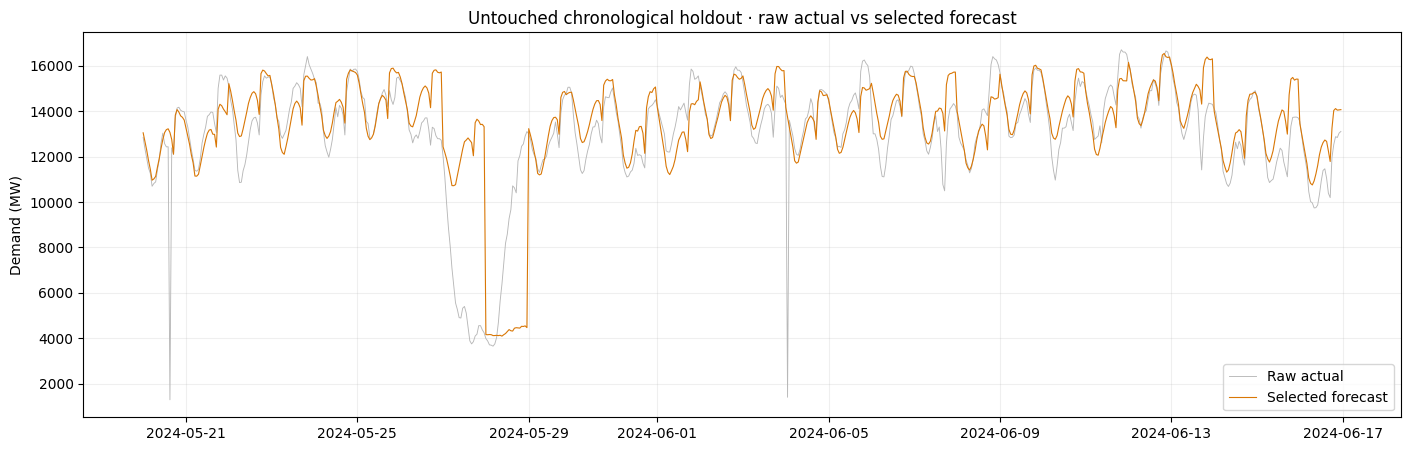

Selected raw holdout WAPE: 7.851% | seasonal-blend raw holdout WAPE: 10.742%


In [17]:
# Fit once at the first holdout origin. Weights stay fixed across the holdout, while each daily origin
# receives newly observed history. This emulates periodic model refresh with daily feature updates.
holdout_start=holdout_origins[0]
train_holdout=samples.loc[(samples.target_ts<=holdout_start)&samples.y.notna()].copy()
holdout_rows=samples.loc[samples.origin_ts.isin(holdout_origins)].copy().sort_values(["origin_ts","horizon"])

needed=ensemble_members if selected_model=="ensemble" else [selected_model]

def fit_selected_members(train_df, label_cutoff, seed_offset=0):
    fitted={}
    for nm in needed:
        if nm in ["seasonal_day","seasonal_week","seasonal_blend"]:
            fitted[nm]=("baseline",None,None,None)
        elif nm in ["lgbm_demand","lgbm_context","cat_demand","cat_context"]:
            algo="lgbm" if nm.startswith("lgbm") else "cat"
            kind="context" if nm.endswith("context") else "demand"
            params=selected_tree_params if nm==selected_tree else None
            obj,feats,best_it=fit_tree(algo,train_df,kind,params=params,early_stop=True)
            fitted[nm]=("tree",obj,feats,best_it)
        elif nm in ["dlinear","patchtst"]:
            train_origins=[o for o in eligible_origins if o<label_cutoff and o+pd.Timedelta(hours=24)<=label_cutoff]
            obj,best_epoch,info=train_neural(nm,train_origins,label_cutoff=label_cutoff,seed=SEED+seed_offset)
            fitted[nm]=("neural",obj,best_epoch,info)
        elif nm=="chronos2":
            if not chronos_available: raise RuntimeError("Chronos-2 selected but not available.")
            fitted[nm]=("chronos",None,None,None)
    return fitted


def predict_members(fitted, origins, frame_rows):
    preds={}
    for name,entry in fitted.items():
        kind=entry[0]
        if kind=="tree":
            _,model,feats,_=entry
            p=predict_tree(model,feats,frame_rows)
            key=frame_rows[["origin_ts","target_ts","horizon"]].copy(); key["pred"]=p
            preds[name]=key
        elif kind=="neural":
            _,model,_,_=entry
            preds[name]=predict_neural(model,origins).rename(columns={"y_pred":"pred"})
        elif kind=="chronos":
            rows=[]
            for o in origins:
                q=chronos_predict(o)
                for h in range(1,25): rows.append({"origin_ts":o,"target_ts":o+pd.Timedelta(hours=h),"horizon":h,"pred":max(0,float(q[0.5][h-1]))})
            preds[name]=pd.DataFrame(rows)
        elif kind=="baseline":
            b=add_baseline_predictions(frame_rows)
            col={"seasonal_day":"pred_seasonal_day","seasonal_week":"pred_seasonal_week","seasonal_blend":"pred_day_week_mean"}[name]
            key=frame_rows[["origin_ts","target_ts","horizon"]].copy(); key["pred"]=b[col].to_numpy(float)
            preds[name]=key
    return preds

fitted_holdout=fit_selected_members(train_holdout,holdout_start,seed_offset=100)
pred_parts=predict_members(fitted_holdout,holdout_origins,holdout_rows)
holdout_pred=holdout_rows[["origin_ts","target_ts","horizon","y_raw","y","label_masked","label_observed"]].copy()
for name,pp in pred_parts.items():
    holdout_pred=holdout_pred.merge(pp[["origin_ts","target_ts","horizon","pred"]].rename(columns={"pred":f"pred_{name}"}),on=["origin_ts","target_ts","horizon"],how="left")

hb=add_baseline_predictions(holdout_rows)[["origin_ts","target_ts","horizon","pred_seasonal_day","pred_seasonal_week","pred_day_week_mean"]]
hb=hb.rename(columns={"pred_seasonal_day":"baseline_seasonal_day",
                      "pred_seasonal_week":"baseline_seasonal_week",
                      "pred_day_week_mean":"baseline_seasonal_blend"})
holdout_pred=holdout_pred.merge(hb,on=["origin_ts","target_ts","horizon"],how="left",validate="one_to_one")
if selected_model=="ensemble":
    component_matrix=np.column_stack([holdout_pred[f"pred_{n}"].to_numpy(float) for n in needed])
    valid_components=np.isfinite(component_matrix).all(axis=1)
    candidate_prediction=np.nanmean(component_matrix,axis=1)
else:
    candidate_prediction=holdout_pred[f"pred_{selected_model}"].to_numpy(float)
    valid_components=np.isfinite(candidate_prediction)

# Any fallback is explicitly recorded; never silently blend a missing model component into the ensemble.
baseline_fallback=holdout_pred.baseline_seasonal_blend.to_numpy(float)
if not np.isfinite(baseline_fallback).all():
    raise RuntimeError("Seasonal fallback is not finite for every holdout row.")
holdout_pred["prediction_fallback_to_seasonal_blend"]=(~valid_components)
holdout_pred["y_pred"]=np.where(valid_components,candidate_prediction,baseline_fallback)
holdout_pred["y_pred"]=np.maximum(0.0,holdout_pred["y_pred"].astype(float))

holdout_rows_out=[]
for name,col in [("selected","y_pred"),("seasonal_day","baseline_seasonal_day"),("seasonal_week","baseline_seasonal_week"),("seasonal_blend","baseline_seasonal_blend")]:
    mr=metric_pack(holdout_pred.y_raw,holdout_pred[col])
    mc=metric_pack(holdout_pred.y,holdout_pred[col])
    holdout_rows_out.append({"model":name,"raw_WAPE_pct":mr["WAPE_pct"],"raw_MAE_MW":mr["MAE"],"raw_RMSE_MW":mr["RMSE"],
                             "raw_Bias_MW":mr["Bias_MW"],"quality_WAPE_pct":mc["WAPE_pct"],"quality_MAE_MW":mc["MAE"],"n_raw":mr["n"],"n_quality":mc["n"]})
holdout_leaderboard=pd.DataFrame(holdout_rows_out)
holdout_leaderboard.to_csv(OUTDIR/"final_holdout_leaderboard.csv",index=False)
display(holdout_leaderboard)
print("Holdout fallback fraction:",round(float(holdout_pred.prediction_fallback_to_seasonal_blend.mean()),4))

horizon_rows=[]
for h,g in holdout_pred.groupby("horizon"):
    mr=metric_pack(g.y_raw,g.y_pred); mc=metric_pack(g.y,g.y_pred)
    horizon_rows.append({"horizon":int(h),"raw_WAPE_pct":mr["WAPE_pct"],"raw_MAE_MW":mr["MAE"],"raw_RMSE_MW":mr["RMSE"],
                         "quality_WAPE_pct":mc["WAPE_pct"],"n_raw":mr["n"]})
holdout_horizon=pd.DataFrame(horizon_rows)
holdout_horizon.to_csv(OUTDIR/"final_holdout_horizon_errors.csv",index=False)
display(holdout_horizon)

# Daily energy and peak errors require all 24 RAW observations.
daily=[]
for o,g in holdout_pred.groupby("origin_ts"):
    g=g.sort_values("horizon")
    if len(g)==24 and g.y_raw.notna().all():
        daily.append({"origin_ts":o,"actual_energy_mwh":g.y_raw.sum(),"pred_energy_mwh":g.y_pred.sum(),
                      "actual_peak_mw":g.y_raw.max(),"pred_peak_mw":g.y_pred.max(),
                      "energy_abs_error_mwh":abs(g.y_raw.sum()-g.y_pred.sum()),
                      "peak_abs_error_mw":abs(g.y_raw.max()-g.y_pred.max())})
daily_report=pd.DataFrame(daily)
daily_report.to_csv(OUTDIR/"final_holdout_daily_peak_energy.csv",index=False)
if len(daily_report):
    print("Daily energy MAE MWh:",mean_absolute_error(daily_report.actual_energy_mwh,daily_report.pred_energy_mwh))
    print("Daily peak MAE MW:",mean_absolute_error(daily_report.actual_peak_mw,daily_report.pred_peak_mw))

fig,ax=plt.subplots(figsize=(17,5))
ax.plot(holdout_pred.target_ts,holdout_pred.y_raw,color="0.72",lw=.65,label="Raw actual")
ax.plot(holdout_pred.target_ts,holdout_pred.y_pred,color="#d97706",lw=.8,label="Selected forecast")
ax.set_title("Untouched chronological holdout · raw actual vs selected forecast")
ax.set_ylabel("Demand (MW)"); ax.grid(alpha=.2); ax.legend(); plt.show()
holdout_pred.to_csv(OUTDIR/"final_holdout_predictions.csv",index=False)

sel_raw=metric_pack(holdout_pred.y_raw,holdout_pred.y_pred)["WAPE_pct"]
base_raw=metric_pack(holdout_pred.y_raw,holdout_pred.baseline_seasonal_blend)["WAPE_pct"]
print(f"Selected raw holdout WAPE: {sel_raw:.3f}% | seasonal-blend raw holdout WAPE: {base_raw:.3f}%")
if not (sel_raw < base_raw):
    warnings.warn("Selected model did not beat the seasonal blend on raw holdout WAPE. Do not claim the ML model is superior; report the baseline honestly.")


## 16 · Empirical residual intervals (P10/P90) and interval evaluation

Untouched raw holdout P10-P90 coverage: 0.4814 (nominal 0.80)
Mean interval width MW: 1062.47


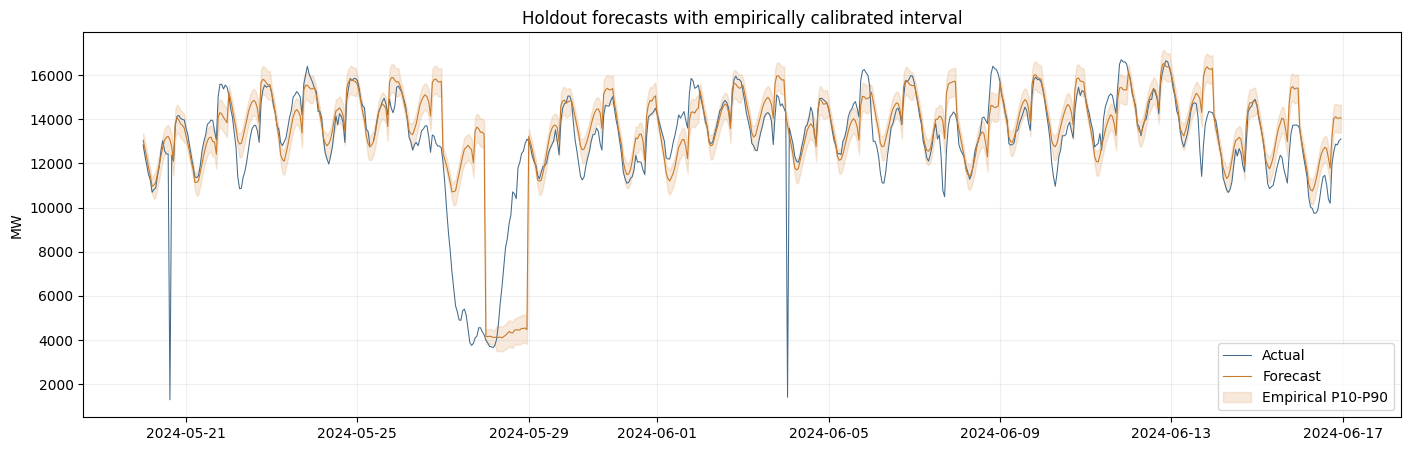

In [18]:
# Calibrate on rolling-origin out-of-time residuals against RAW observations. These are empirical intervals, not a guarantee
# of 80% coverage under future distribution shift. Coverage and mean width are both reported.
# Calibrate only from the selected model's out-of-time predictions, not from a mixture of all candidates.
calibration_models=needed if selected_model=="ensemble" else [selected_model]
cv_matrix=cv_predictions.loc[cv_predictions.model.isin(calibration_models)].pivot_table(
    index=["fold","origin_ts","target_ts","horizon","y_raw"],columns="model",values="y_pred",aggfunc="first").reset_index()
cv_matrix=cv_matrix.loc[cv_matrix.y_raw.notna()].copy()
if selected_model=="ensemble":
    if not all(n in cv_matrix.columns for n in calibration_models): raise RuntimeError("Selected ensemble lacks complete CV calibration predictions.")
    cv_matrix["selected_pred"]=np.nanmean(np.column_stack([cv_matrix[n].to_numpy(float) for n in calibration_models]),axis=1)
else:
    cv_matrix["selected_pred"]=cv_matrix[selected_model].to_numpy(float)
cv_matrix=cv_matrix.loc[np.isfinite(cv_matrix.selected_pred)].copy()
cv_matrix["residual"]=cv_matrix.y_raw-cv_matrix.selected_pred
# Pool neighbouring horizons to avoid unstable tail estimates from only a few observations per horizon.
def horizon_bucket(h): return int((int(h)-1)//6)  # 1-6, 7-12, 13-18, 19-24
cv_matrix["h_bucket"]=cv_matrix.horizon.map(horizon_bucket)
pooled_quantiles=np.quantile(cv_matrix.residual.dropna(),[.10,.90])
calibration={}
for b,g in cv_matrix.groupby("h_bucket"):
    r=g.residual.dropna().to_numpy(float)
    if len(r)>=60: calibration[int(b)]=tuple(np.quantile(r,[.10,.90]))
    else: calibration[int(b)]=tuple(pooled_quantiles)
for b in range(4): calibration.setdefault(b,tuple(pooled_quantiles))

holdout_pred["p10"]=np.maximum(0.0,np.minimum(holdout_pred.y_pred.to_numpy(float),[
    holdout_pred.y_pred.iloc[i]+calibration[horizon_bucket(h)][0] for i,h in enumerate(holdout_pred.horizon)]))
holdout_pred["p90"]=np.maximum(holdout_pred.y_pred.to_numpy(float),[
    holdout_pred.y_pred.iloc[i]+calibration[horizon_bucket(h)][1] for i,h in enumerate(holdout_pred.horizon)])
valid=holdout_pred.y_raw.notna()
coverage80=float(((holdout_pred.loc[valid,"y_raw"]>=holdout_pred.loc[valid,"p10"])&(holdout_pred.loc[valid,"y_raw"]<=holdout_pred.loc[valid,"p90"])).mean())
width=float((holdout_pred.loc[valid,"p90"]-holdout_pred.loc[valid,"p10"]).mean())
print("Untouched raw holdout P10-P90 coverage:",round(coverage80,4),"(nominal 0.80)")
print("Mean interval width MW:",round(width,2))
fig,ax=plt.subplots(figsize=(17,5))
ax.plot(holdout_pred.target_ts,holdout_pred.y_raw,color="#446b8a",lw=.75,label="Actual")
ax.plot(holdout_pred.target_ts,holdout_pred.y_pred,color="#c77b2d",lw=.8,label="Forecast")
ax.fill_between(holdout_pred.target_ts,holdout_pred.p10,holdout_pred.p90,color="#d88a38",alpha=.18,label="Empirical P10-P90")
ax.set_title("Holdout forecasts with empirically calibrated interval")
ax.set_ylabel("MW"); ax.grid(alpha=.2); ax.legend(); plt.show()
holdout_pred.to_csv(OUTDIR/"final_holdout_predictions_with_intervals.csv",index=False)

## 17 · Refit the selected model at the requested hidden-date origin

,timestamp,demand_mw,p10,p90
0,2024-06-17 00:00:00,12863.460938,12521.038379,13190.555225
1,2024-06-17 01:00:00,12364.828125,12022.405566,12691.922412
2,2024-06-17 02:00:00,11873.310547,11530.887988,12200.404834
3,2024-06-17 03:00:00,11478.865234,11136.442676,11805.959521
4,2024-06-17 04:00:00,10979.594727,10637.172168,11306.689014
5,2024-06-17 05:00:00,10315.340820,9972.918262,10642.435107
6,2024-06-17 06:00:00,9993.035156,9368.696875,10493.053711
7,2024-06-17 07:00:00,9908.085938,9283.747656,10408.104492
8,2024-06-17 08:00:00,10035.943359,9411.605078,10535.961914
9,2024-06-17 09:00:00,10240.304688,9615.966406,10740.323242


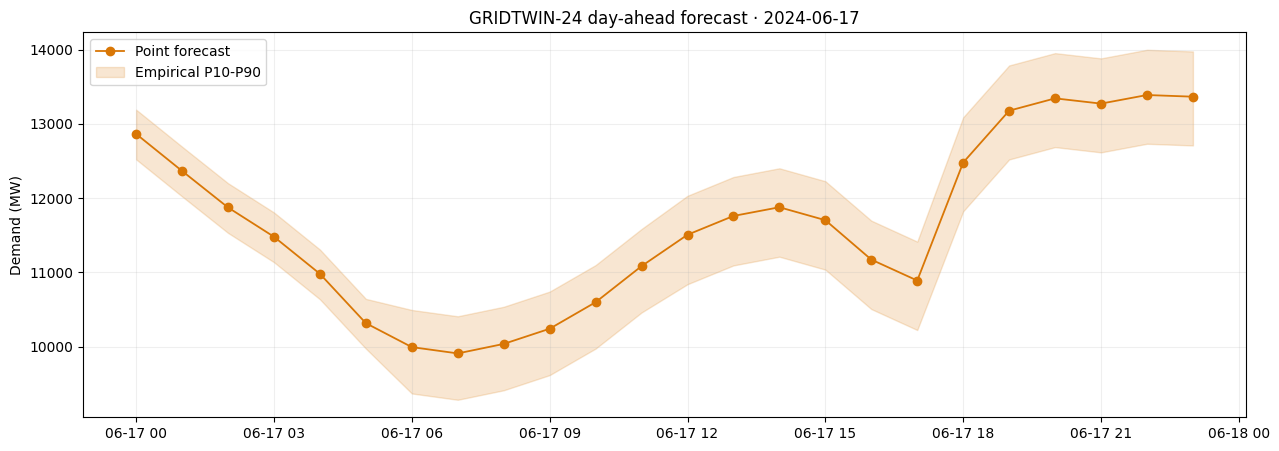

In [19]:
# Final deployment fit uses every quality-reviewed target label available through the exact issue origin.
final_train=samples.loc[(samples.target_ts<=forecast_origin)&samples.y.notna()].copy()
future_pos=builder.index.get_indexer([forecast_origin])[0]
if future_pos<0: raise ValueError("Forecast origin missing from hourly grid.")
future_rows=pd.DataFrame(builder.build(future_pos,include_labels=False))
if len(future_rows)!=24: raise RuntimeError(f"Expected 24 horizons, got {len(future_rows)}")

final_members={}
for nm in needed:
    if nm in ["seasonal_day","seasonal_week","seasonal_blend"]:
        final_members[nm] = ("baseline", None, None, None)
    elif nm in ["lgbm_demand","lgbm_context","cat_demand","cat_context"]:
        algo="lgbm" if nm.startswith("lgbm") else "cat"; kind="context" if nm.endswith("context") else "demand"
        params=selected_tree_params if nm==selected_tree else None
        # Refit with all labels; use best_iteration from the selected tuning/CV model when available.
        model,feats,best_it=fit_tree(algo,final_train,kind,params=params,early_stop=True)
        final_members[nm]=("tree",model,feats,best_it)
    elif nm in ["dlinear","patchtst"]:
        fit_origins=[o for o in eligible_origins if o<forecast_origin and o+pd.Timedelta(hours=24)<=forecast_origin]
        model,best_epoch,info=train_neural(nm,fit_origins,label_cutoff=forecast_origin,max_epochs=NEURAL_MAX_EPOCHS,patience=NEURAL_PATIENCE,seed=SEED+500)
        final_members[nm]=("neural",model,best_epoch,info)
    elif nm=="chronos2":
        if not chronos_available: raise RuntimeError("Chronos-2 selected but is unavailable.")
        final_members[nm]=("chronos",None,None,None)

final_components={}
for nm,entry in final_members.items():
    if entry[0]=="tree":
        final_components[nm]=predict_tree(entry[1],entry[2],future_rows)
    elif entry[0]=="neural":
        q=predict_neural(entry[1],[forecast_origin]).sort_values("horizon")
        if len(q)!=24: raise RuntimeError(f"Neural forecast incomplete for {nm}.")
        final_components[nm]=q.y_pred.to_numpy(float)
    elif entry[0]=="chronos":
        final_components[nm]=np.maximum(0,chronos_predict(forecast_origin)[0.5])
    elif entry[0]=="baseline":
        fb=add_baseline_predictions(future_rows)
        col={"seasonal_day":"pred_seasonal_day","seasonal_week":"pred_seasonal_week","seasonal_blend":"pred_day_week_mean"}[nm]
        final_components[nm]=np.maximum(0,fb[col].to_numpy(float))

if not final_components or any(len(v)!=24 or not np.isfinite(v).all() for v in final_components.values()):
    raise RuntimeError("At least one selected final model component did not produce 24 finite predictions.")
if selected_model=="ensemble":
    final_point=np.mean([final_components[nm] for nm in needed],axis=0)
else:
    final_point=final_components[selected_model]
final_point=np.maximum(np.asarray(final_point,dtype=float),0)

# Use CV residual quantiles, with the point estimate forced to stay inside its interval.
final_p10=np.array([max(0.0,min(p,p+calibration[horizon_bucket(h)][0])) for h,p in enumerate(final_point,1)])
final_p90=np.array([max(p,p+calibration[horizon_bucket(h)][1],final_p10[h-1]) for h,p in enumerate(final_point,1)])
forecast_timestamps=pd.date_range(forecast_day,periods=24,freq="h")
forecast_submission=pd.DataFrame({"timestamp":forecast_timestamps,"demand_mw":final_point,"p10":final_p10,"p90":final_p90})
forecast_submission.to_csv(OUTDIR/"sample_forecast_one_origin.csv",index=False)
display(forecast_submission)

fig,ax=plt.subplots(figsize=(15,5))
ax.plot(forecast_timestamps,final_point,color="#d97706",marker="o",lw=1.3,label="Point forecast")
ax.fill_between(forecast_timestamps,final_p10,final_p90,color="#d97706",alpha=.18,label="Empirical P10-P90")
ax.set_title(f"GRIDTWIN-24 day-ahead forecast · {forecast_day.date()}")
ax.set_ylabel("Demand (MW)"); ax.grid(alpha=.2); ax.legend(); plt.show()

## 18 · Feature importance and horizon diagnostics

Selected model has no tree feature importance.


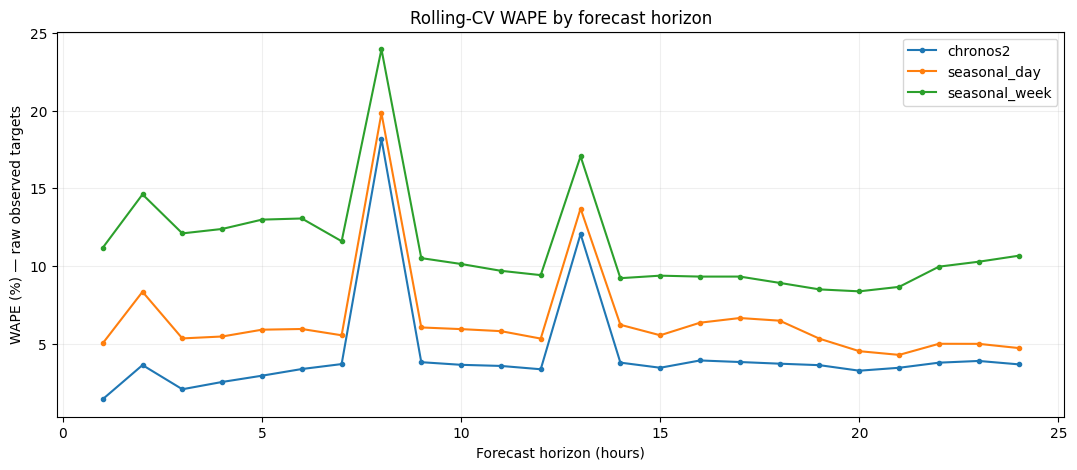

In [20]:
# Feature importances are descriptive, not causal. For the selected tree candidates only.
fi=[]
for nm,entry in final_members.items():
    if entry[0]!="tree": continue
    _,model,feats,_=entry
    if nm.startswith("lgbm"):
        fi.append(pd.DataFrame({"model":nm,"feature":feats,"gain":model.booster_.feature_importance(importance_type="gain"),"split":model.booster_.feature_importance(importance_type="split")}))
    else:
        fi.append(pd.DataFrame({"model":nm,"feature":feats,"gain":model.get_feature_importance(),"split":np.nan}))
if fi:
    feature_importance=pd.concat(fi,ignore_index=True)
    feature_importance.to_csv(OUTDIR/"feature_importance.csv",index=False)
    display(feature_importance.sort_values("gain",ascending=False).groupby("model").head(25))
else: print("Selected model has no tree feature importance.")

# CV error by horizon, plus the final holdout error profile.
cv_horizon=[]
for (model,h),g in cv_predictions.groupby(["model","horizon"]):
    mr=metric_pack(g.y_raw,g.y_pred); mc=metric_pack(g.y,g.y_pred)
    cv_horizon.append({"model":model,"horizon":int(h),"raw_WAPE_pct":mr["WAPE_pct"],"raw_MAE_MW":mr["MAE"],
                       "quality_WAPE_pct":mc["WAPE_pct"],"quality_MAE_MW":mc["MAE"],"n_raw":mr["n"]})
cv_horizon=pd.DataFrame(cv_horizon)
cv_horizon.to_csv(OUTDIR/"cv_horizon_errors.csv",index=False)
fig,ax=plt.subplots(figsize=(13,5))
for nm in [selected_single,"seasonal_day","seasonal_week"]:
    g=cv_horizon[cv_horizon.model==nm]
    if len(g): ax.plot(g.horizon,g.raw_WAPE_pct,marker="o",ms=3,label=nm)
ax.set_xlabel("Forecast horizon (hours)"); ax.set_ylabel("WAPE (%) — raw observed targets"); ax.set_title("Rolling-CV WAPE by forecast horizon")
ax.grid(alpha=.2); ax.legend(); plt.show()

## 19 · Automated stress tests and final submission checks

In [21]:
# Small synthetic tests target the pipeline's highest-risk failure modes.
def test_timestamp_validation():
    base=pd.DataFrame({"timestamp":pd.date_range("2024-01-01",periods=24*40,freq="h"),"demand_mw":np.arange(24*40,dtype=float)})
    h,fd,fo,last,missing,dups,co,after=make_hourly_history(base,"2024-02-05")
    assert fo==pd.Timestamp("2024-02-04 23:00:00")
    assert h.index.max()==fo and not (h.index>fo).any()
    bad=base.copy(); bad["timestamp"]=bad["timestamp"].astype(str); bad.loc[3,"timestamp"]="not-a-date"
    try: make_hourly_history(bad,"2024-02-05"); raise AssertionError("Malformed timestamp was accepted")
    except ValueError: pass
    tz=base.copy(); tz["timestamp"]=tz.timestamp.dt.tz_localize("UTC")
    try: make_hourly_history(tz,"2024-02-05"); raise AssertionError("Timezone-aware timestamps were accepted")
    except ValueError: pass
    dup=pd.concat([base,base.iloc[[5]]],ignore_index=True)
    _,_,_,_,_,n,_,_=make_hourly_history(dup,"2024-02-05")
    assert n==1
    conflict=pd.concat([base,base.iloc[[5]].assign(demand_mw=9999)],ignore_index=True)
    try: make_hourly_history(conflict,"2024-02-05"); raise AssertionError("Conflicting duplicate timestamp was averaged")
    except ValueError: pass
    off=base.copy(); off.loc[7,"timestamp"] += pd.Timedelta(minutes=15)
    try: make_hourly_history(off,"2024-02-05"); raise AssertionError("Off-hour timestamp was silently rounded")
    except ValueError: pass


def test_causal_anomaly_and_regime_logic():
    ix=pd.date_range("2020-01-01",periods=24*400,freq="h")
    rng=np.random.default_rng(7)
    yy=pd.Series(10000+500*np.sin(np.arange(len(ix))*2*np.pi/24)+rng.normal(0,80,len(ix)),index=ix)
    yy.iloc[24*250+10]=121000.0
    yy.iloc[24*300:24*300+8]=40000.0  # >3x the old level: must be recognised as a persistent shift
    aud,clean=causal_target_quality(yy)
    spike_ix=ix[24*250+10]
    assert bool(aud.loc[spike_ix,"masked_for_model"]),"Isolated typo-like spike was not masked"
    shift_ix=ix[24*300+7]
    assert not bool(aud.loc[shift_ix,"masked_for_model"]),"Persistent level shift was incorrectly masked after confirmation"
    assert yy.loc[spike_ix]==121000.0,"Raw value must remain unchanged"


def test_future_feature_perturbation():
    ix=pd.date_range("2021-01-01",periods=24*100,freq="h")
    rng=np.random.default_rng(9)
    fr=pd.DataFrame({"demand_mw":10000+rng.normal(0,100,len(ix)),"generation_mw":10100+rng.normal(0,100,len(ix))},index=ix)
    yr=fr.demand_mw.copy(); ym=yr.copy(); yi=yr.copy(); miss=yr.isna().astype(float)
    b1=DayAheadFeatureBuilder(fr,yr,ym,yi,miss,["generation_mw"])
    pos=24*70+23; a=b1.build(pos,False)
    fr2=fr.copy(); fr2.iloc[pos+1:]=fr2.iloc[pos+1:]*23+444
    yr2=yr.copy(); ym2=ym.copy(); yi2=yi.copy()
    yr2.iloc[pos+1:]=yr2.iloc[pos+1:]*23+444; ym2.iloc[pos+1:]=ym2.iloc[pos+1:]*23+444; yi2.iloc[pos+1:]=yi2.iloc[pos+1:]*23+444
    b2=DayAheadFeatureBuilder(fr2,yr2,ym2,yi2,miss,["generation_mw"]); z=b2.build(pos,False)
    for ra,rb in zip(a,z):
        for key in ra:
            if key in {"origin_ts","target_ts","y","y_raw","label_masked","label_observed"}: continue
            va,vb=ra[key],rb[key]
            if pd.isna(va) and pd.isna(vb): continue
            assert np.isclose(va,vb,equal_nan=True) if isinstance(va,(int,float,np.number)) else va==vb


def test_missing_gap_no_future_fill():
    ix=pd.date_range("2022-01-01",periods=24*60,freq="h")
    s=pd.Series(np.arange(len(ix),dtype=float),index=ix)
    s.iloc[500:540]=np.nan
    audit,clean=causal_target_quality(s)
    inp=clean.ffill(limit=3)
    recent=clean.shift(1).rolling(168,min_periods=24).median()
    weekly=clean.shift(168)
    inp=inp.fillna(recent).fillna(weekly).fillna(audit.past_hour_of_week_median)
    assert inp.iloc[500:540].notna().all(),"Long missing interval was not handled by past-only fallback"
    # Before any observation exists, no future value may be pulled backwards.
    leading=pd.Series([np.nan,np.nan,1.0,2.0],index=pd.date_range("2020-01-01",periods=4,freq="h"))
    leading_ff=leading.ffill(limit=3)
    assert leading_ff.iloc[:2].isna().all(),"Past-only fill pulled future information backwards"


def test_metrics_and_submission():
    m=metric_pack([100,100,100],[100,110,90])
    assert np.isclose(m["MAE"],20/3) and np.isfinite(m["WAPE_pct"])
    zero=metric_pack([0,0],[1,1])
    assert np.isnan(zero["WAPE_pct"]), "WAPE must be undefined when the denominator is zero."
    assert np.isfinite(zero["MAE"])
    ts=pd.date_range(forecast_day,periods=24,freq="h")
    p=np.maximum(0,np.asarray(final_point,dtype=float))
    lo=np.maximum(0,np.minimum(p,p-100)); hi=np.maximum(p,p+100)
    z=pd.DataFrame({"timestamp":ts,"demand_mw":p,"p10":lo,"p90":hi})
    assert len(z)==24 and z.timestamp.is_monotonic_increasing and z.timestamp.is_unique
    assert np.isfinite(z[["demand_mw","p10","p90"]]).all().all()
    assert (z.p10<=z.demand_mw).all() and (z.demand_mw<=z.p90).all()


def test_hidden_date_cutoff_invariance():
    ix=pd.date_range("2024-01-01",periods=24*55,freq="h")
    base=pd.DataFrame({"timestamp":ix,"demand_mw":10000+100*np.sin(np.arange(len(ix))*2*np.pi/24),
                       "generation_mw":10100+80*np.cos(np.arange(len(ix))*2*np.pi/24)})
    date="2024-02-10"
    h1,fd1,fo1,last1,miss1,dup1,co1,after1=make_hourly_history(base,date)
    altered=base.copy()
    cut=altered.timestamp>=pd.Timestamp(date)
    altered.loc[cut,"demand_mw"]=-999999
    altered.loc[cut,"generation_mw"]=9e9
    # Deliberately conflicting duplicate and non-numeric measurement strictly after the cutoff.
    future_row=altered.loc[cut].iloc[[0]].copy()
    if len(future_row):
        future_row["demand_mw"]="not-a-number"
        altered=pd.concat([altered,future_row],ignore_index=True)
    h2,fd2,fo2,last2,miss2,dup2,co2,after2=make_hourly_history(altered,date)
    pd.testing.assert_frame_equal(h1,h2)
    assert fd1==fd2 and fo1==fo2 and h2.index.max()==fo2
    assert after2 >= int(cut.sum())


def test_fold_temporal_boundaries():
    for f in folds:
        start=f[0]
        tr=samples.loc[(samples.target_ts<=start)&samples.y.notna()]
        va=samples.loc[samples.origin_ts.isin(f)&samples.y.notna()]
        assert len(tr)>0 and len(va)>0
        assert tr.target_ts.max()<=start
        assert va.target_ts.min()>start
        assert set(tr.origin_ts).isdisjoint(set(f))


def test_baseline_and_model_components_are_finite():
    sample_origins=eligible_origins[-3:]
    small=samples.loc[samples.origin_ts.isin(sample_origins)].copy()
    bp=add_baseline_predictions(small)
    assert np.isfinite(bp[["pred_seasonal_day","pred_seasonal_week","pred_day_week_mean"]].to_numpy(float)).mean()>.95
    assert len(forecast_submission)==24
    assert set(final_components)==set(needed)
    assert all(len(v)==24 and np.isfinite(v).all() for v in final_components.values())


def test_neural_architecture_shapes():
    if "torch" not in globals(): return
    xx=torch.randn(3,LOOKBACK,2,device=DEVICE)
    with torch.no_grad():
        for model in [DLinear24().to(DEVICE),PatchTST24().to(DEVICE)]:
            pp,mu,sd=model(xx)
            assert pp.shape==(3,24) and mu.shape==(3,1) and sd.shape==(3,1)
            assert torch.isfinite(pp).all()
            del model
    del xx
    if torch.cuda.is_available(): torch.cuda.empty_cache()



def test_anomaly_detector_is_causal():
    ix=pd.date_range("2020-01-01",periods=24*180,freq="h")
    rng=np.random.default_rng(17)
    y=pd.Series(9000+300*np.sin(np.arange(len(ix))*2*np.pi/24)+rng.normal(0,40,len(ix)),index=ix)
    y.iloc[-24*10+3]=121000
    audit_a,clean_a=causal_target_quality(y)
    cut=len(y)-24*5
    y2=y.copy(); y2.iloc[cut:]=y2.iloc[cut:]*31+987654
    audit_b,clean_b=causal_target_quality(y2)
    pd.testing.assert_frame_equal(audit_a.iloc[:cut],audit_b.iloc[:cut])
    pd.testing.assert_series_equal(clean_a.iloc[:cut],clean_b.iloc[:cut])


def test_missing_hour_reindex_and_long_gap():
    ix=pd.date_range("2024-01-01",periods=24*50,freq="h")
    df=pd.DataFrame({"timestamp":ix,"demand_mw":10000+np.sin(np.arange(len(ix)))})
    df=df.drop(index=list(range(24*20,24*20+30))).reset_index(drop=True)
    h,fd,fo,last,missing,dups,co,after=make_hourly_history(df,"2024-02-20")
    assert len(missing)>=30
    assert h.index.freq is not None or h.index.inferred_freq=="h"
    assert h.loc[missing].demand_mw.isna().all()


def test_invalid_forecast_dates_fail_closed():
    for bad in ["not-a-date","2024/02/05","2024-02-05T12:00:00","2024-02-05T00:00:00Z"]:
        try:
            parse_iso_forecast_date(bad)
            raise AssertionError(f"Invalid forecast date accepted: {bad}")
        except ValueError:
            pass


def test_feature_origin_and_target_lag_contract():
    for pos in valid_positions[-min(20,len(valid_positions)):]:
        rr=builder.build(pos,include_labels=False)
        origin=hourly.index[pos]
        assert len(rr)==24
        for row in rr:
            assert row["target_ts"]>origin
            for lag in TARGET_ALIGNED_LAGS:
                source=row["target_ts"]-pd.Timedelta(hours=lag)
                assert source<=origin


def test_no_infinite_features_or_negative_target_labels():
    numeric=samples.select_dtypes(include=[np.number])
    assert not np.isinf(numeric.to_numpy(dtype=float)).any()
    assert (samples.loc[samples.y.notna(),"y"]>=0).all()


def test_holdout_is_not_used_for_tuning():
    assert set(tune_origins).isdisjoint(set(holdout_origins))
    assert max(tune_origins)<min(holdout_origins)
    assert max(o+pd.Timedelta(hours=24) for o in tune_origins)<=min(holdout_origins)


def test_prediction_fallback_is_explicit():
    assert "prediction_fallback_to_seasonal_blend" in holdout_pred.columns
    assert holdout_pred.prediction_fallback_to_seasonal_blend.dtype==bool
    assert np.isfinite(holdout_pred.y_pred).all()


tests=[test_timestamp_validation,test_causal_anomaly_and_regime_logic,test_anomaly_detector_is_causal,
       test_future_feature_perturbation,test_missing_gap_no_future_fill,test_missing_hour_reindex_and_long_gap,
       test_invalid_forecast_dates_fail_closed,test_metrics_and_submission,test_hidden_date_cutoff_invariance,
       test_fold_temporal_boundaries,test_feature_origin_and_target_lag_contract,test_no_infinite_features_or_negative_target_labels,
       test_holdout_is_not_used_for_tuning,test_baseline_and_model_components_are_finite,
       test_prediction_fallback_is_explicit,test_neural_architecture_shapes]
for test in tests:
    test(); print("PASS",test.__name__)
print(f"All {len(tests)} stress-test groups passed.")

PASS test_timestamp_validation
PASS test_causal_anomaly_and_regime_logic
PASS test_anomaly_detector_is_causal
PASS test_future_feature_perturbation
PASS test_missing_gap_no_future_fill
PASS test_missing_hour_reindex_and_long_gap
PASS test_invalid_forecast_dates_fail_closed
PASS test_metrics_and_submission
PASS test_hidden_date_cutoff_invariance
PASS test_fold_temporal_boundaries
PASS test_feature_origin_and_target_lag_contract
PASS test_no_infinite_features_or_negative_target_labels
PASS test_holdout_is_not_used_for_tuning
PASS test_baseline_and_model_components_are_finite
PASS test_prediction_fallback_is_explicit
PASS test_neural_architecture_shapes
All 16 stress-test groups passed.


/tmp/ipykernel_1427/3854513073.py:59: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=layers,norm=nn.LayerNorm(d_model))


## 20 · Export the final forecast, fitted models and research report

In [24]:
import joblib

# Required organiser-compatible file.
assert list(forecast_submission.columns)==["timestamp","demand_mw","p10","p90"]
assert len(forecast_submission)==24
assert forecast_submission.timestamp.is_monotonic_increasing and forecast_submission.timestamp.is_unique
assert forecast_submission.timestamp.iloc[0]==forecast_day
assert forecast_submission.timestamp.iloc[-1]==forecast_day+pd.Timedelta(hours=23)
assert np.isfinite(forecast_submission[["demand_mw","p10","p90"]]).all().all()
assert (forecast_submission.demand_mw>=0).all()
assert (forecast_submission.p10<=forecast_submission.demand_mw+1e-8).all()
assert (forecast_submission.demand_mw<=forecast_submission.p90+1e-8).all()
assert hourly.index.max()==forecast_origin

# Persist all reproducibility evidence.
cv_predictions.to_csv(OUTDIR/"rolling_cv_predictions.csv",index=False)
leaderboard.to_csv(OUTDIR/"rolling_cv_leaderboard.csv",index=False)
cv_horizon.to_csv(OUTDIR/"cv_horizon_errors.csv",index=False)
holdout_pred.to_csv(OUTDIR/"final_holdout_predictions_with_intervals.csv",index=False)
holdout_leaderboard.to_csv(OUTDIR/"final_holdout_leaderboard.csv",index=False)
holdout_horizon.to_csv(OUTDIR/"final_holdout_horizon_errors.csv",index=False)
daily_report.to_csv(OUTDIR/"final_holdout_daily_peak_energy.csv",index=False)
anomaly_audit.to_csv(OUTDIR/"data_anomaly_audit.csv")
coverage.to_csv(OUTDIR/"column_coverage_audit.csv")

model_manifest={}
for name,entry in final_members.items():
    if entry[0]=="tree":
        _,model,feats,best_it=entry
        joblib.dump({"model":model,"features":feats,"model_name":name,"best_iteration":best_it},OUTDIR/f"{name}.joblib")
        model_manifest[name]={"type":"tree","file":f"{name}.joblib","features":feats,"best_iteration":best_it}
    elif entry[0]=="neural":
        _,model,best_epoch,info=entry
        torch.save({"state_dict":model.state_dict(),"model_name":name,"best_epoch":best_epoch,"lookback":LOOKBACK},OUTDIR/f"{name}.pt")
        model_manifest[name]={"type":"torch","file":f"{name}.pt","best_epoch":best_epoch,"training_info":info}

calibration_json={str(k):[float(v[0]),float(v[1])] for k,v in calibration.items()}
(OUTDIR/"calibration_offsets.json").write_text(json.dumps(calibration_json,indent=2))

selected_metrics=metric_pack(holdout_pred.y_raw,holdout_pred.y_pred)
# Fix: use baseline_seasonal_blend instead of pred_seasonal_blend
base_metrics=metric_pack(holdout_pred.y_raw,holdout_pred.baseline_seasonal_blend)
metadata={
    "dataset_url":DATA_URL,"dataset_sha256":DATA_SHA256,"git_blob_sha1":GIT_BLOB_SHA1,
    "raw_rows":int(len(raw)),"modeling_rows":int(len(hourly)),
    "first_timestamp":str(hourly.index.min()),"issue_origin":str(forecast_origin),"forecast_date":str(forecast_day.date()),
    "missing_hour_slots":int(len(missing_hour_index)),"rows_after_issue_origin_excluded":int(ROWS_AFTER_ISSUE_ORIGIN),"masked_gross_error_count":int(anomaly_audit.masked_for_model.sum()),
    "selected_model":selected_model,"ensemble_members":needed,
    "tuned_tree":selected_tree,"tree_params":selected_tree_params,"optuna_score":optuna_best_score,
    "holdout_selected_raw_metrics":selected_metrics,"holdout_seasonal_blend_raw_metrics":base_metrics,
    "holdout_interval_coverage_p10_p90_raw":coverage80,"holdout_interval_mean_width_mw":width,
    "device":DEVICE,"torch":torch.__version__,"models_saved":model_manifest,
    "holdout_prediction_fallback_fraction":float(holdout_pred.prediction_fallback_to_seasonal_blend.mean()),
    "selection_metric":"raw_observation_WAPE_with_fold_stability_penalty",
    "interpretation":"Regression metrics are dataset/split-specific. No 99% accuracy or near-perfect forecasting claim is made. Raw observations are primary for model selection and holdout reporting; quality-reviewed metrics are sensitivity analyses."
}
(OUTDIR/"run_metadata.json").write_text(json.dumps(metadata,indent=2,default=str))

report=f"""# GRIDTWIN-24 Training Report

- Dataset SHA-256: `{DATA_SHA256}`
- Forecast date: `{forecast_day.date()}`
- Issue origin: `{forecast_origin}`
- Selected model: `{selected_model}`
- Device: `{DEVICE}`
- Missing hourly slots through issue origin: `{len(missing_hour_index)}`
- Rows excluded after issue origin: `{ROWS_AFTER_ISSUE_ORIGIN}`
- Quality-screened isolated gross-error labels: `{int(anomaly_audit.masked_for_model.sum())}`

## Untouched holdout — raw observations (primary evaluation)

- Selected model WAPE: `{selected_metrics['WAPE_pct']:.4f}%`
- Selected model MAE: `{selected_metrics['MAE']:.2f} MW`
- Selected model RMSE: `{selected_metrics['RMSE']:.2f} MW`
- Selected model bias: `{selected_metrics['Bias_MW']:.2f} MW`
- Seasonal-blend baseline WAPE: `{base_metrics['WAPE_pct']:.4f}%`

## Uncertainty

- Calibrated against raw out-of-time residuals. Empirical P10–P90 holdout coverage: `{coverage80:.4f}` (nominal target 0.80)
- Mean interval width: `{width:.2f} MW`

## Interpretation

The holdout is the final generalisation check and was not used for tuning or selection. If the selected model does not beat the seasonal baseline on raw holdout WAPE, do not claim an improvement. Review the horizon errors, data anomaly audit and fold stability. The prediction interval is empirical; it is not a guarantee under distribution shift.
"""
(OUTDIR/"TRAINING_REPORT.md").write_text(report)

zip_path=Path("/content/GRIDTWIN24_FINAL_OUTPUTS.zip")
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for p in OUTDIR.rglob("*"):
        if p.is_file(): z.write(p,p.relative_to(OUTDIR))
print("Forecast:",OUTDIR/"sample_forecast_one_origin.csv")
print("Artifacts:",OUTDIR)
print("ZIP:",zip_path,"MB",round(zip_path.stat().st_size/1e6,2))
print("Model manifest:",model_manifest)

Forecast: /content/GRIDTWIN24_FINAL_OUTPUTS/sample_forecast_one_origin.csv
Artifacts: /content/GRIDTWIN24_FINAL_OUTPUTS
ZIP: /content/GRIDTWIN24_FINAL_OUTPUTS.zip MB 3.01
Model manifest: {}


## 21 · Optional Google Drive copy

In [25]:
SAVE_TO_DRIVE=False
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        import shutil
        dest=Path("/content/drive/MyDrive/GRIDTWIN24_FINAL_OUTPUTS")
        dest.mkdir(parents=True,exist_ok=True)
        shutil.copy2(zip_path,dest/zip_path.name)
        print("Copied to",dest/zip_path.name)
    except Exception as e:
        print("Drive copy failed; local outputs remain available:",type(e).__name__,str(e)[:500])

# Uncomment in Colab to download the result archive:
# from google.colab import files
# files.download(str(zip_path))

In [26]:
from google.colab import files
import os

# Direct file download to user's local device
zip_file = '/content/GRIDTWIN24_FINAL_OUTPUTS.zip'
if os.path.exists(zip_file):
    print(f'Downloading {zip_file} ({os.path.getsize(zip_file)/1e6:.2f} MB)...')
    files.download(zip_file)
else:
    print('Target ZIP archive not found. Please re-run cell 1990b918 to re-generate outputs.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 22 · Research interpretation — required before publication or a demo claim

Report the dataset hash, forecast-origin convention, missing-hour count, anomaly policy, feature availability, model-selection folds, tuning window, holdout window, MAE, RMSE, WAPE, bias, horizon-wise error, daily-peak error, daily-energy error, interval coverage and interval width.

Do not report `100 − WAPE` as generic “accuracy”. A WAPE of 5% is not equivalent to a 95% classification accuracy. Show the baseline comparison on the **same raw holdout timestamps**. If the model loses to the seasonal baseline, either keep the baseline or investigate why the model did not generalise.

A T4 GPU accelerates the neural and foundation-model challengers; it does not make a model automatically more accurate. A large Transformer can overfit this dataset. Early stopping, masked losses, rolling-origin evaluation, and an untouched holdout are the controls against that.

**Known limits:** the dataset README does not declare a timezone, holidays, weather forecasts, or the operational time at which each covariate becomes available. The notebook therefore preserves the source clock and uses operational covariates only as historical lags/aggregates. A hidden ISO date must be entered exactly in `FORECAST_DATE` before running all cells.